# Online Machine Learning - River and CapyMOA 
Doha JOUAY - M2 Data Science

This lab explores online machine learning using River and CapyMOA. We compare several regression and classification algorithms on real and synthetic data streams, study how they react to concept drift, and evaluate their predictive performance and computational cost. We also experiment with stream clustering and online AutoML using CapyMOA.

# 1. Environment Set up

The experiments were implemented in Python using River 0.26.1 and CapyMOA 0.15.1. River provides incremental learning algorithms and drift detectors, while CapyMOA provides additional streaming methods through a Python interface to Java-based implementations.

NumPy and pandas are used for data handling, Matplotlib for visualization, and scikit-learn for some evaluation metrics and preprocessing.

To make the experiments reproducible, we use a fixed random seed of 42. All models are evaluated using the prequential (test-then-train) protocol: each observation is first used to make a prediction and evaluate the model, then used to update it.

In [127]:
import time
from collections import deque
from datetime import date, datetime
from numbers import Number
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from sklearn.feature_extraction import DictVectorizer

import river, capymoa
from river import datasets, tree, forest, linear_model, neighbors, preprocessing, optim, metrics, drift
from river import multiclass
from river.drift import binary as binary_drift
from capymoa.stream import NumpyStream
from capymoa.evaluation import prequential_evaluation
from capymoa.classifier import (HoeffdingTree as CapyHT,
    AdaptiveRandomForestClassifier as CapyARF, KNN as CapyKNN,
    SGDClassifier as CapySGD)

SEED = 42
REAL_N = 1000
SYNTH_N = 3000
WINDOW = 150
DRIFT_POINTS = (1000, 2000)
np.random.seed(SEED)
Path('results').mkdir(exist_ok=True)
print('River:', river.__version__, '| CapyMOA:', capymoa.__version__)
print('Real samples:', REAL_N, '| Synthetic samples:', SYNTH_N)

River: 0.26.1 | CapyMOA: 0.15.1
Real samples: 1000 | Synthetic samples: 3000


### Experimental settings

We limit the experiments to **1,000 observations per real dataset**, when available, and **3,000 observations for synthetic datasets**. ChickWeights contains only 578 observations, so the complete dataset is used. These limits keep execution times manageable while allowing us to compare the models under the same conditions.

For the synthetic streams, we introduce two abrupt concept drifts at observations **1,000 and 2,000**. This gives us known change points against which to evaluate the drift detectors.

The input features are converted into numerical values when necessary. Dates are represented using components such as month, weekday and hour, while categorical features are encoded as indicator variables. When required, online standardization is applied within the learning pipeline.

We measure both predictive performance and computational cost. Total running time includes the complete evaluation loop, while model latency measures the time spent on prediction and training, expressed in milliseconds per observation. For the later River-CapyMOA comparison, we use end-to-end runtime per observation to make the timing definition consistent.

In [128]:
def features(x):
    """Convert incoming features to numbers without fitting on future data."""
    out = {}
    for key, value in x.items():
        if value is None:
            continue
        if isinstance(value, (date, datetime)):
            out[f'{key}_month'] = float(value.month)
            out[f'{key}_weekday'] = float(value.weekday())
            if isinstance(value, datetime):
                out[f'{key}_hour'] = float(value.hour)
        elif isinstance(value, Number):
            if np.isfinite(float(value)):
                out[str(key)] = float(value)
        else:
            out[f'{key}={value}'] = 1.0
    return out


def friedman_drift():
    rng = np.random.default_rng(SEED)
    for i in range(SYNTH_N):
        z = rng.uniform(size=10)
        a = 10*np.sin(np.pi*z[0]*z[1]) + 20*(z[2]-.5)**2 + 10*z[3] + 5*z[4]
        b = 15*np.sin(np.pi*z[0]*z[1]) + 6*(z[2]-.5)**2 + 15*z[3] + 2*z[4]
        c = 3*np.sin(np.pi*z[0]*z[1]) + 25*(z[2]-.5)**2 + 3*z[3] + 15*z[4]
        y = a if i < DRIFT_POINTS[0] else b if i < DRIFT_POINTS[1] else c
        yield {f'x{j}':float(v) for j,v in enumerate(z)}, float(y+rng.normal(0,.5))


def sea_drift():
    rng = np.random.default_rng(SEED)
    for i in range(SYNTH_N):
        z = rng.uniform(0,10,size=3)
        threshold = 8 if i < DRIFT_POINTS[0] else 9 if i < DRIFT_POINTS[1] else 7
        y = int(z[0]+z[1] <= threshold)
        if rng.random() < .05:
            y = 1-y
        yield {f'x{j}':float(v) for j,v in enumerate(z)}, y


def bars(frame, metric, title, higher=False):
    frame.pivot(index='dataset', columns='model', values=metric).plot(kind='bar', figsize=(10,4))
    plt.title(title)
    plt.ylabel(metric + (' (higher is better)' if higher else ' (lower is better)'))
    plt.xlabel('')
    plt.xticks(rotation=0)
    plt.grid(axis='y', alpha=.2)
    plt.tight_layout()
    plt.show()


def best_by_dataset(frame, metric, higher=False):
    for name, group in frame.groupby('dataset'):
        row = group.loc[group[metric].idxmax() if higher else group[metric].idxmin()]
        print(f'{name}: {row["model"]} ({metric} = {row[metric]:.3f})')

# 2. Part 1: River Regression

## 2.1 Regression methods

We start by comparing four online regression algorithms from River, each using a different learning approach:

- **Hoeffding Tree:** an incremental decision tree that learns by splitting the data as new observations arrive.
- **Adaptive Random Forest (ARF):** an ensemble of five trees designed to handle changes in data streams.
- **Linear Regression + Adam:** a linear model trained with an adaptive optimizer. We also apply online standardization to the input features.
- **KNN Regressor:** an instance-based method that predicts using the five nearest neighbors.

For the datasets, we use three real datasets (**TrumpApproval, ChickWeights and Bikes**) and one synthetic dataset (**Friedman drift**). The real datasets allow us to compare the models on different prediction problems, while Friedman drift lets us observe how they react to changes in the relationship between features and targets.

The Friedman stream contains 3,000 observations, with two abrupt concept drifts at observations 1,000 and 2,000. For the real datasets, we use up to 1,000 observations, except ChickWeights, which contains 578.

The objective is to compare both prediction quality and computational cost, and see whether the same algorithm performs well across different datasets.

In [129]:
REG_DATA = {
    'TrumpApproval': lambda: datasets.TrumpApproval(),
    'ChickWeights': lambda: datasets.ChickWeights(),
    'Bikes': lambda: datasets.Bikes(),
    'Friedman drift': friedman_drift,
}
REG_MODELS = {
    'Hoeffding Tree': lambda: tree.HoeffdingTreeRegressor(grace_period=100, leaf_prediction='mean'),
    'Adaptive RF': lambda: forest.ARFRegressor(n_models=5, seed=SEED),
    'Linear + Adam': lambda: preprocessing.StandardScaler() | linear_model.LinearRegression(optimizer=optim.Adam(lr=.01)),
    'KNN': lambda: preprocessing.StandardScaler() | neighbors.KNNRegressor(n_neighbors=5),
}
for name, factory in REG_DATA.items():
    x, y = next(iter(factory()))
    print(f'{name}: {len(x)} features, target example = {y}')

TrumpApproval: 6 features, target example = 43.75505
ChickWeights: 3 features, target example = 42
Bikes: 8 features, target example = 1
Friedman drift: 10 features, target example = 19.21422278263975


## 2.2 Comparison

We evaluate each model using the **prequential (test-then-train)** approach: each observation is first used for prediction and evaluation, then for updating the model.

We compare three regression metrics: MAE, RMSE and R². We also measure running time and latency to evaluate the computational cost of each algorithm.

Each experiment starts with a fresh model, and all four models receive the same observations in the same order for a given dataset. This makes the comparisons more consistent.

The results are summarized in the following table, followed by separate figures for each metric.

In [130]:
def run_regression(make_model, make_data, limit):
    model = make_model()
    mae, rmse, r2 = metrics.MAE(), metrics.RMSE(), metrics.R2()
    recent, history, errors = deque(maxlen=WINDOW), [], []
    model_seconds = 0.0
    start = time.perf_counter()
    n = 0
    for n, (raw_x, y) in enumerate(make_data(), start=1):
        if n > limit:
            n -= 1
            break
        x = features(raw_x)
        tick = time.perf_counter()
        pred = model.predict_one(x)
        model_seconds += time.perf_counter()-tick
        if pred is not None:
            mae.update(y,pred); rmse.update(y,pred); r2.update(y,pred)
            error = float(y-pred)
            errors.append((n,error)); recent.append(error**2)
        tick = time.perf_counter()
        model.learn_one(x,y)
        model_seconds += time.perf_counter()-tick
        if n % 50 == 0 and recent:
            history.append({'instance':n,'rolling RMSE':np.sqrt(np.mean(recent))})
    return ({'MAE':mae.get(),'RMSE':rmse.get(),'R2':r2.get(),
             'runtime (s)':time.perf_counter()-start,
             'latency (ms)':1000*model_seconds/n,
             'observations':n}, pd.DataFrame(history), errors)

REG_ROWS, REG_CURVES = [], {}
for ds, make_data in REG_DATA.items():
    REG_CURVES[ds] = {}
    for name, make_model in REG_MODELS.items():
        summary, curve, _ = run_regression(make_model,make_data,SYNTH_N if ds=='Friedman drift' else REAL_N)
        REG_ROWS.append({'dataset':ds,'model':name,**summary})
        REG_CURVES[ds][name] = curve
    pd.DataFrame(REG_ROWS).to_csv('results/river_regression.csv',index=False)
    print('Finished:',ds)
reg_results = pd.DataFrame(REG_ROWS)
display(reg_results.round(3))

Finished: TrumpApproval
Finished: ChickWeights
Finished: Bikes
Finished: Friedman drift


,dataset,model,MAE,RMSE,R2,runtime (s),latency (ms),observations
0,TrumpApproval,Hoeffding Tree,1.568000e+00,2.204000e+00,-6.590000e-01,0.344,0.315,1000
1,TrumpApproval,Adaptive RF,1.423622e+09,4.501887e+10,-6.922087e+20,0.906,0.867,1000
2,TrumpApproval,Linear + Adam,2.412000e+00,6.617000e+00,-1.395300e+01,0.046,0.024,1000
3,TrumpApproval,KNN,6.420000e-01,1.595000e+00,1.310000e-01,1.110,1.076,1000
4,ChickWeights,Hoeffding Tree,4.354200e+01,6.293800e+01,2.140000e-01,0.027,0.034,578
5,ChickWeights,Adaptive RF,3.266700e+01,4.834900e+01,5.360000e-01,0.423,0.700,578
6,ChickWeights,Linear + Adam,2.992300e+01,4.121700e+01,6.630000e-01,0.020,0.018,578
7,ChickWeights,KNN,2.509500e+01,3.972400e+01,6.870000e-01,0.879,1.498,578
8,Bikes,Hoeffding Tree,4.158000e+00,5.867000e+00,6.800000e-02,0.097,0.045,1000
9,Bikes,Adaptive RF,8.759900e+01,2.647719e+03,-1.897498e+05,0.566,0.493,1000


### 2.2.1 Mean Absolute Error (MAE)

MAE measures the average absolute difference between predicted and actual values. A lower MAE means that predictions are closer to the true values.

The results show that the best-performing model depends on the dataset:

- **TrumpApproval:** KNN obtains the lowest MAE (0.642).
- **ChickWeights:** KNN also performs best, with an MAE of 25.095.
- **Bikes:** Linear Regression + Adam performs best (3.722).
- **Friedman drift:** Adaptive Random Forest achieves the lowest MAE (2.482).

KNN performs particularly well on TrumpApproval and ChickWeights, while the linear model works better on Bikes. On the synthetic nonlinear dataset, the ensemble achieves the best results.

This already suggests that there is no single regression method that works best for every stream.

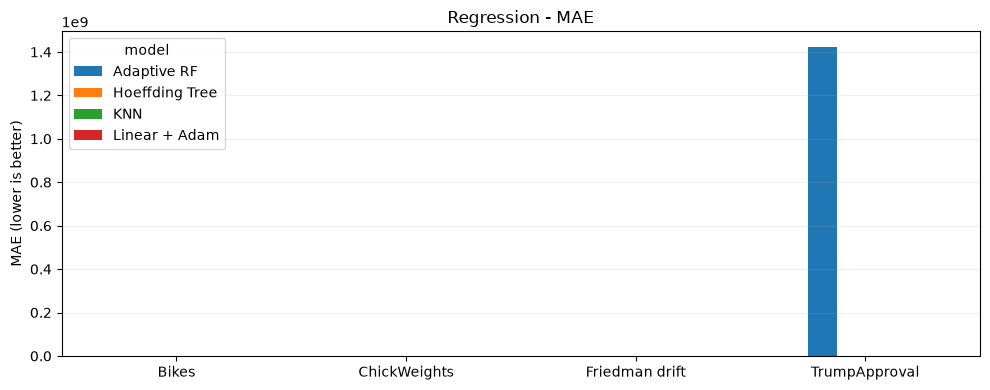

Bikes: Linear + Adam (MAE = 3.722)
ChickWeights: KNN (MAE = 25.095)
Friedman drift: Adaptive RF (MAE = 2.482)
TrumpApproval: KNN (MAE = 0.642)


In [131]:
bars(reg_results,'MAE','Regression - MAE'); best_by_dataset(reg_results,'MAE')

### 2.2.2 Root Mean Squared Error (RMSE)

RMSE also measures prediction error, but it penalizes large mistakes more strongly than MAE. This makes it useful for identifying models that occasionally produce very inaccurate predictions.

The ranking is similar to what we observed with MAE:

- KNN achieves the lowest RMSE on TrumpApproval (1.595) and ChickWeights (39.724).
- Linear Regression + Adam performs best on Bikes (4.840).
- Adaptive Random Forest performs best on Friedman drift (3.212).

However, Adaptive Random Forest produces extremely large RMSE values on TrumpApproval (approximately 4.5 × 10¹⁰) and Bikes (approximately 2,648). These values are much higher than those of the other models.

This suggests that the ensemble may be producing some extreme predictions. Since RMSE squares the errors, even a small number of very large mistakes can strongly affect the final score. We investigate this behavior further in the diagnostic plots below.

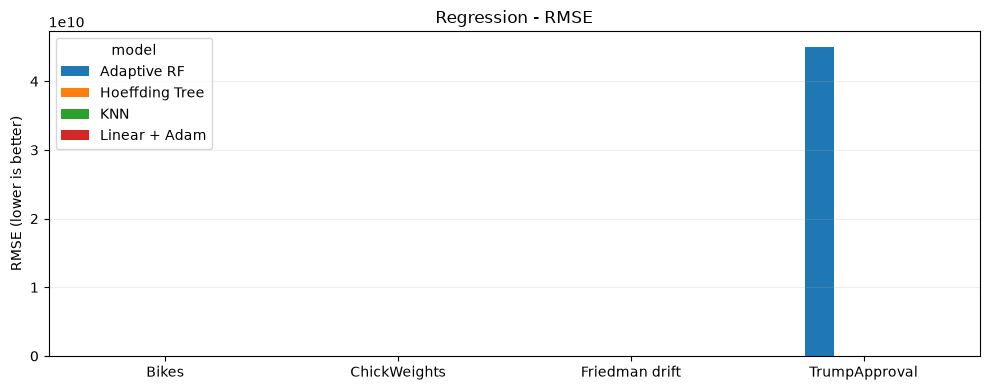

Bikes: Linear + Adam (RMSE = 4.840)
ChickWeights: KNN (RMSE = 39.724)
Friedman drift: Adaptive RF (RMSE = 3.212)
TrumpApproval: KNN (RMSE = 1.595)


In [132]:
bars(reg_results,'RMSE','Regression - RMSE'); best_by_dataset(reg_results,'RMSE')

### 2.2.3 R² Score

R² measures how well the model explains variations in the target compared with predicting its mean. A score closer to 1 indicates better performance, while a negative value means that the model performs worse than this baseline.

The best R² values are:

- **TrumpApproval:** KNN, with R² = 0.131.
- **ChickWeights:** KNN, with R² = 0.687.
- **Bikes:** Linear Regression + Adam, with R² = 0.366.
- **Friedman drift:** Adaptive Random Forest, with R² = 0.705.

The strongest results are obtained on ChickWeights and Friedman drift, where the best models explain around 70% of the target variance.

TrumpApproval is more difficult in this experiment, since even the best model achieves a relatively low R². This means that KNN has the lowest error among the tested models, but still explains only a small proportion of the target variation.

Adaptive Random Forest also produces extremely negative R² values on TrumpApproval and Bikes, consistent with its unusually large RMSE values.

Overall, the R² results support the conclusions from MAE and RMSE.

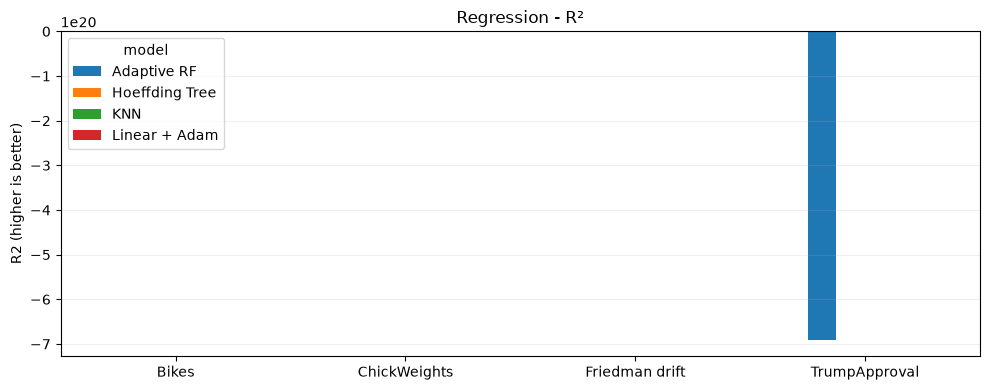

Bikes: Linear + Adam (R2 = 0.366)
ChickWeights: KNN (R2 = 0.687)
Friedman drift: Adaptive RF (R2 = 0.705)
TrumpApproval: KNN (R2 = 0.131)


In [133]:
bars(reg_results,'R2','Regression - R²',higher=True); best_by_dataset(reg_results,'R2',higher=True)

### 2.2.4 Running time and latency

Besides prediction accuracy, we also compare computational cost. Total running time measures how long each experiment takes, while model latency measures the average time spent predicting and training on one observation.

Linear Regression + Adam is the fastest model on all four datasets. For example, on Friedman drift, it takes only **0.259 seconds**, compared with 3.640 seconds for Adaptive Random Forest and 5.019 seconds for KNN.

A similar pattern appears on Bikes, where Linear Regression + Adam takes 0.090 seconds, while KNN requires 1.482 seconds.

KNN is generally one of the slowest methods because it needs to search through stored observations to make predictions. Adaptive Random Forest also requires more computation than a single tree because it maintains several learners.

These results show a trade-off between accuracy and computational cost. On Friedman drift, Adaptive Random Forest achieves the lowest prediction error, but Linear Regression + Adam is much faster while remaining reasonably accurate.

For real-time applications, this difference in execution cost can be important. However, the timing values come from a single run and may vary depending on system activity.

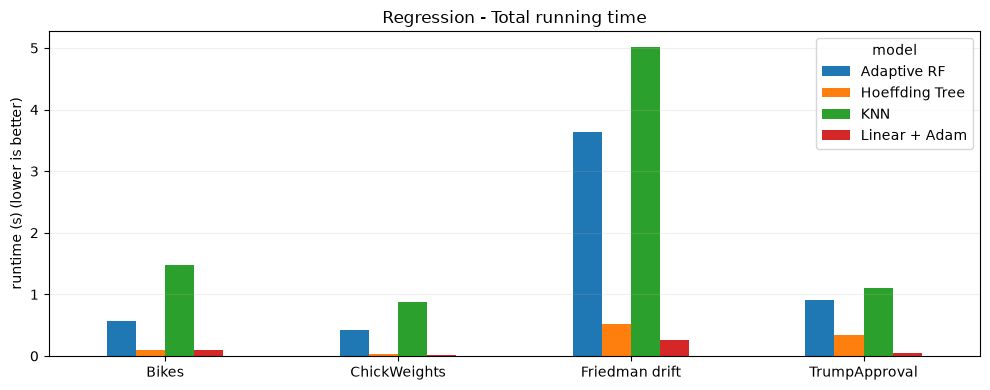

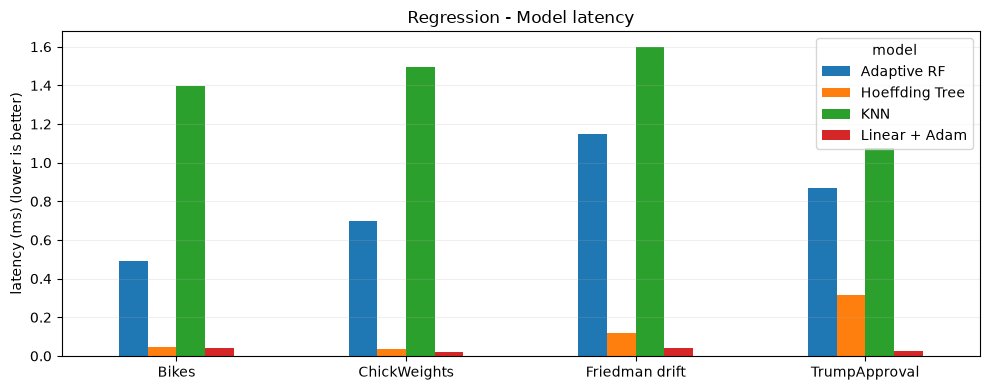

In [134]:
bars(reg_results,'runtime (s)','Regression - Total running time'); bars(reg_results,'latency (ms)','Regression - Model latency')

### 2.2.5 Learning curves

The previous metrics summarize performance over the entire stream, but they do not show how the models behave over time.

To examine this, we plot the **rolling RMSE**, computed over the most recent observations. This helps us identify periods where prediction errors increase or decrease.

The Friedman drift dataset is particularly interesting because we know that the underlying relationship changes at observations 1,000 and 2,000, marked by the dashed vertical lines.

These plots complement the cumulative metrics by showing short-term changes that may be hidden in the final average. We use them again in the following section to investigate concept drift.

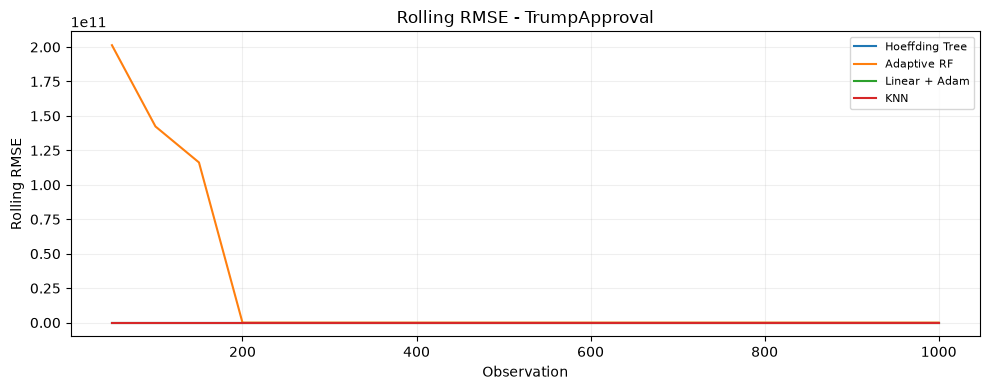

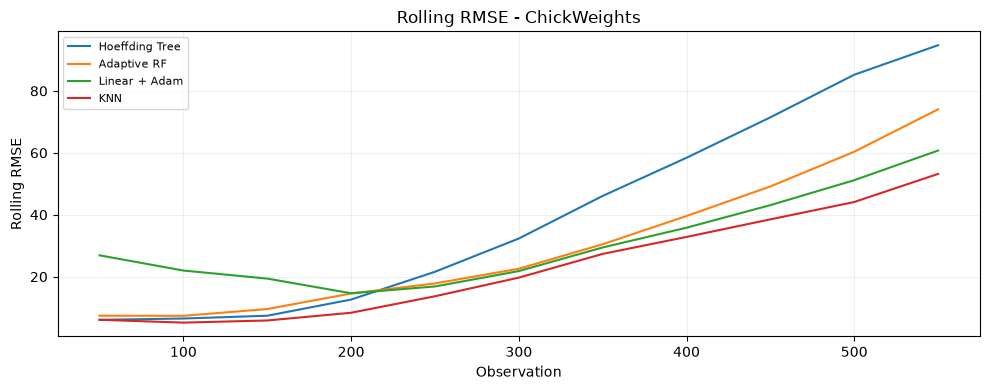

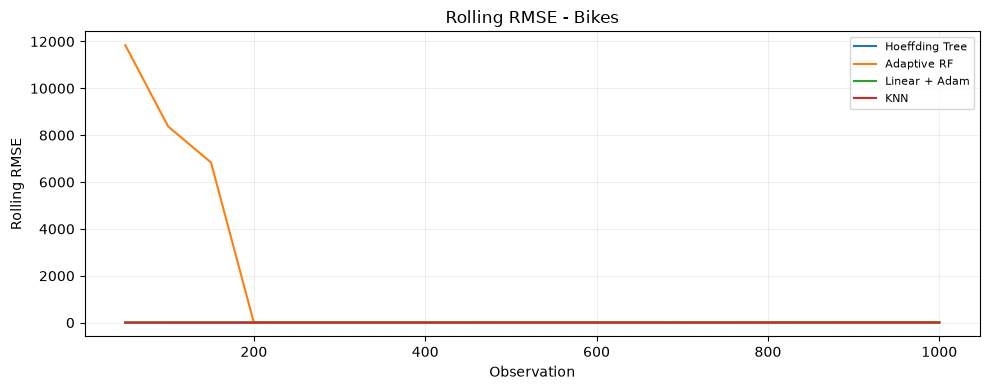

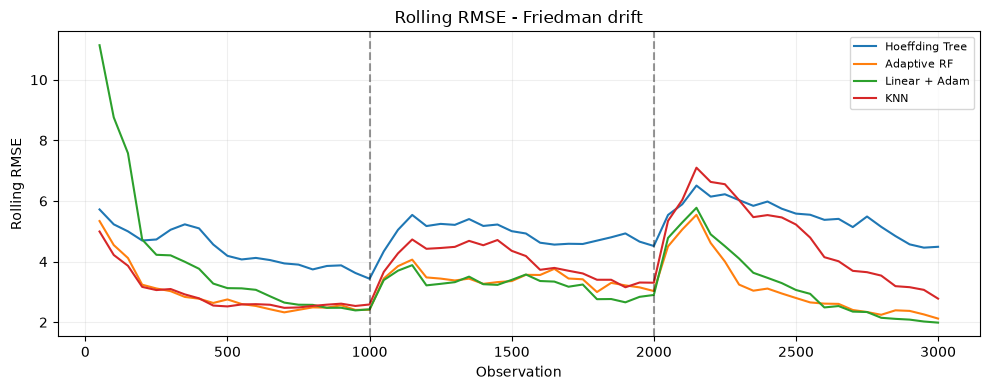

In [135]:
for ds, curves in REG_CURVES.items():
    plt.figure(figsize=(10,4))
    for name, history in curves.items():
        plt.plot(history['instance'],history['rolling RMSE'],label=name)
    if ds=='Friedman drift':
        for p in DRIFT_POINTS: plt.axvline(p,color='black',ls='--',alpha=.4)
    plt.title('Rolling RMSE - '+ds)
    plt.xlabel('Observation'); plt.ylabel('Rolling RMSE')
    plt.legend(fontsize=8); plt.grid(alpha=.2); plt.tight_layout(); plt.show()

**Overall regression observations**

The results show that model performance depends strongly on the dataset. KNN performs best on TrumpApproval and ChickWeights, Linear Regression + Adam performs best on Bikes, and Adaptive Random Forest achieves the lowest error on Friedman drift.

The ensemble is particularly effective on the nonlinear synthetic stream, but it is not consistently better than simpler approaches. Linear Regression + Adam is much faster and provides competitive performance on several datasets.

One unexpected result is the very poor performance of Adaptive Random Forest on TrumpApproval and Bikes. To understand this, we examine the distribution of its prediction errors in more detail.


Dataset: TrumpApproval
Maximum absolute error: 1423621760742.2717
Median absolute error: 0.5235109220355767
Largest absolute prediction: 1423621760785.982


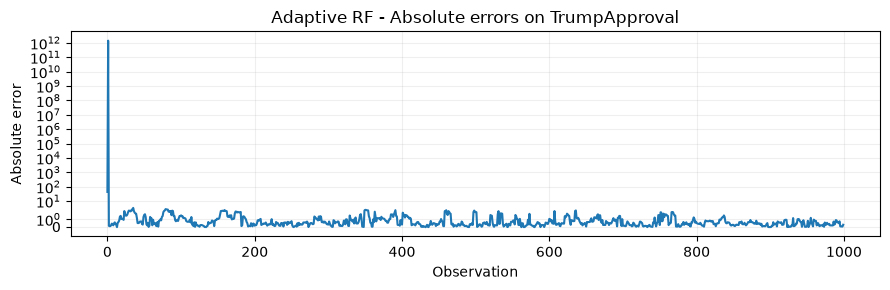


Dataset: Bikes
Maximum absolute error: 83728.060928
Median absolute error: 2.7184751093419846
Largest absolute prediction: 83731.060928


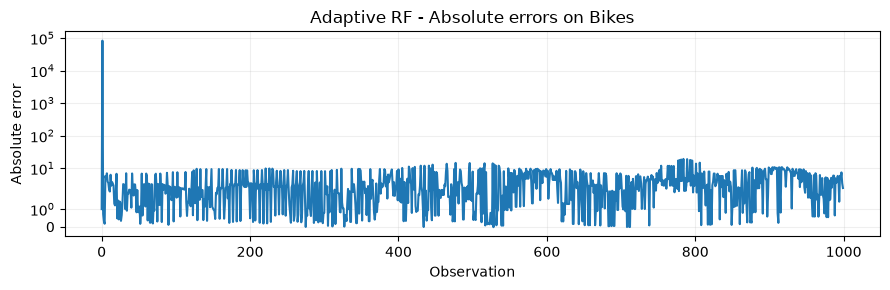

In [136]:
# Investigate extreme Adaptive RF predictions

for dataset_name in ['TrumpApproval', 'Bikes']:

    model = REG_MODELS['Adaptive RF']()
    errors = []
    predictions = []

    for i, (raw_x, y) in enumerate(REG_DATA[dataset_name]()):

        if i >= REAL_N:
            break

        x = features(raw_x)
        pred = model.predict_one(x)

        if pred is not None:
            predictions.append(pred)
            errors.append(abs(y - pred))

        model.learn_one(x, y)

    print(f"\nDataset: {dataset_name}")
    print("Maximum absolute error:", max(errors))
    print("Median absolute error:", np.median(errors))
    print("Largest absolute prediction:", max(abs(p) for p in predictions))

    plt.figure(figsize=(9, 3))
    plt.plot(errors)
    plt.title(f'Adaptive RF - Absolute errors on {dataset_name}')
    plt.xlabel('Observation')
    plt.ylabel('Absolute error')
    plt.yscale('symlog')
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

### Additional analysis: Adaptive Random Forest prediction errors

To investigate the unusually large RMSE values, we looked at the absolute prediction errors of Adaptive Random Forest on TrumpApproval and Bikes.

On TrumpApproval, the median absolute error is only **0.524**, but the maximum reaches approximately **1.42 × 10¹²**. On Bikes, the median is **2.718**, while the maximum reaches **83,728**.

This is an important difference: most predictions are much closer to the targets than the RMSE suggests, but some extremely large errors dominate the overall metric.

The diagnostic plots confirm that the model produces extreme prediction errors in these experiments. The exact cause has not been established, so these results should be interpreted as instability in the tested configuration rather than evidence that Adaptive Random Forest is generally unsuitable for these datasets.

This also shows why it is useful to compare several error metrics instead of relying only on RMSE.

## 2.3 Drift Detection

Concept drift occurs when the relationship between input features and the target changes over time. In online learning, this can reduce prediction accuracy because the model has learned from an earlier data distribution.

To compare drift detectors, we use the synthetic Friedman stream, with two known changes at observations **1,000 and 2,000**.

We test three detectors:

- **ADWIN**, which monitors changes in the statistics of an adaptive window.
- **Page-Hinkley**, which detects sustained changes in a monitored signal.
- **KSWIN**, which compares distributions across windows using a statistical test.

All three detectors receive the same sequence of absolute prediction errors produced by a Hoeffding Tree. This allows us to compare their behavior on a common signal.

We examine the number of alarms, their positions relative to the true drifts, and the detection delays.

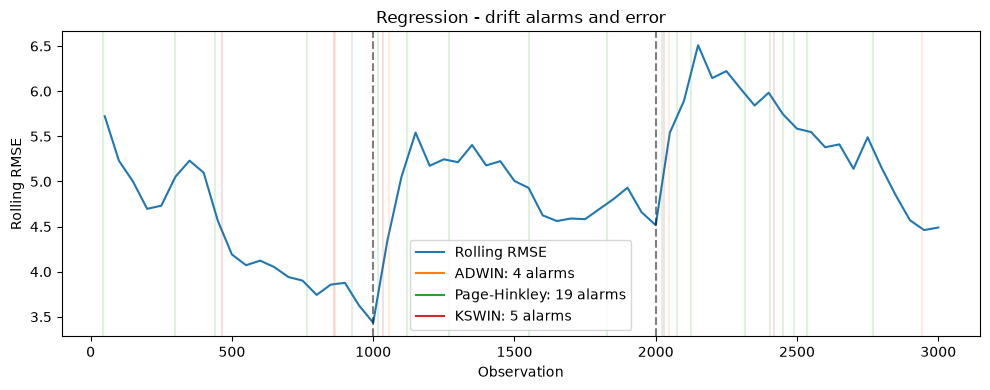

,detector,alarms,positions
0,ADWIN,4,"[864, 1056, 2048, 2944]"
1,Page-Hinkley,19,"[45, 298, 439, 765, 924, 1018, 1121, 1269, 155..."
2,KSWIN,5,"[464, 863, 1035, 2030, 2419]"


In [137]:
_, reg_curve, reg_errors = run_regression(REG_MODELS['Hoeffding Tree'],friedman_drift,SYNTH_N)
REG_DETECTORS = {'ADWIN':lambda:drift.ADWIN(),
                 'Page-Hinkley':lambda:drift.PageHinkley(),
                 'KSWIN':lambda:drift.KSWIN(seed=SEED)}

def alarm_positions(errors, make_detector, absolute=False):
    detector = make_detector(); alarms=[]
    for n, err in errors:
        detector.update(abs(err) if absolute else err)
        if detector.drift_detected: alarms.append(n)
    return alarms

reg_alarms = {name:alarm_positions(reg_errors,factory,True) for name,factory in REG_DETECTORS.items()}
plt.figure(figsize=(10,4))
plt.plot(reg_curve['instance'],reg_curve['rolling RMSE'],label='Rolling RMSE')
for p in DRIFT_POINTS: plt.axvline(p,color='black',ls='--',alpha=.5)
for j,(name,alarms) in enumerate(reg_alarms.items()):
    for a in alarms: plt.axvline(a,color=['tab:orange','tab:green','tab:red'][j],alpha=.14)
    plt.plot([],[],color=['tab:orange','tab:green','tab:red'][j],label=f'{name}: {len(alarms)} alarms')
plt.title('Regression - drift alarms and error')
plt.xlabel('Observation');plt.ylabel('Rolling RMSE');plt.legend();plt.tight_layout();plt.show()
display(pd.DataFrame([{'detector':k,'alarms':len(v),'positions':str(v[:20])} for k,v in reg_alarms.items()]))

### Drift detection results

The three detectors successfully raise alarms near both known drift points, but their behavior differs.

**ADWIN** detects the first drift at observation 1,056 (delay of 56 observations) and the second at 2,048 (delay of 48 observations). It produces four alarms in total.

**Page-Hinkley** is the fastest detector in this experiment, with delays of only 18 and 24 observations. However, it raises 19 alarms in total, suggesting that it is more sensitive to fluctuations in prediction error.

**KSWIN** detects the two changes with delays of 35 and 30 observations and raises five alarms overall.

Using a 300-observation matching window after each true drift, we obtain 2 unmatched alarms for ADWIN, 17 for Page-Hinkley and 3 for KSWIN.

Overall, Page-Hinkley reacts fastest, but ADWIN appears to offer a better balance between detection delay and the number of alarms. The unmatched alarms are not necessarily all false positives, but they do not correspond to the known drift points under our evaluation rule.

### Effect of resetting the model

We also compare two Hoeffding Tree strategies: one that continues learning without intervention and another that resets the model whenever ADWIN detects a change.

Resetting allows the model to start learning again under the new concept, but it also removes information previously acquired. We compare their rolling RMSE to see whether the resets lead to faster recovery after drift.

In [138]:
# Detection delays for known drift positions

def drift_delay_table(alarms_dict, true_drifts, tolerance=300):
    rows = []

    for detector, alarms in alarms_dict.items():
        used_alarms = set()

        for drift_point in true_drifts:
            candidates = [
                a for a in alarms
                if drift_point <= a <= drift_point + tolerance
                and a not in used_alarms
            ]

            if candidates:
                detected = min(candidates)
                used_alarms.add(detected)
                delay = detected - drift_point
            else:
                detected = None
                delay = None

            rows.append({
                'Detector': detector,
                'True drift': drift_point,
                'Detected at': detected,
                'Delay': delay
            })

        rows.append({
            'Detector': detector,
            'True drift': 'Unmatched alarms',
            'Detected at': len(alarms) - len(used_alarms),
            'Delay': None
        })

    return pd.DataFrame(rows)


reg_delay_results = drift_delay_table(
    reg_alarms,
    DRIFT_POINTS
)

display(reg_delay_results)

,Detector,True drift,Detected at,Delay
0,ADWIN,1000,1056,56.0
1,ADWIN,2000,2048,48.0
2,ADWIN,Unmatched alarms,2,NaN
3,Page-Hinkley,1000,1018,18.0
4,Page-Hinkley,2000,2024,24.0
5,Page-Hinkley,Unmatched alarms,17,NaN
6,KSWIN,1000,1035,35.0
7,KSWIN,2000,2030,30.0
8,KSWIN,Unmatched alarms,3,NaN


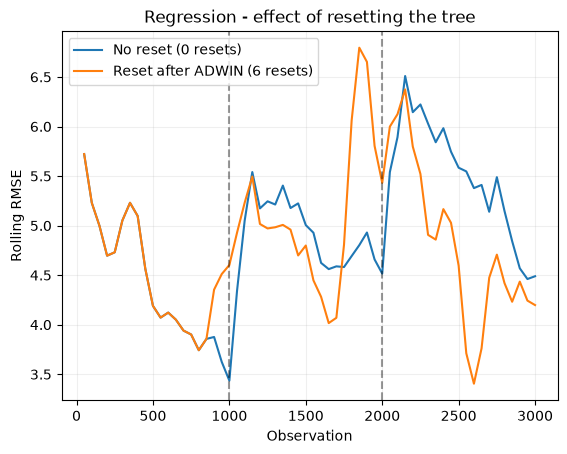

In [139]:
def regression_reset(reset):
    model=REG_MODELS['Hoeffding Tree'](); detector=drift.ADWIN()
    recent=deque(maxlen=WINDOW); xs=[]; ys=[]; alarms=[]
    for i,(x,y) in enumerate(friedman_drift(),1):
        pred=model.predict_one(x)
        if pred is not None:
            error=abs(y-pred); recent.append(error**2); detector.update(error)
            if reset and detector.drift_detected:
                alarms.append(i); model=REG_MODELS['Hoeffding Tree'](); detector=drift.ADWIN()
        model.learn_one(x,y)
        if i%50==0 and recent: xs.append(i);ys.append(np.sqrt(np.mean(recent)))
    return xs,ys,alarms

for title,do_reset in [('No reset',False),('Reset after ADWIN',True)]:
    xs,ys,alarms=regression_reset(do_reset)
    plt.plot(xs,ys,label=f'{title} ({len(alarms)} resets)')
for p in DRIFT_POINTS:plt.axvline(p,color='black',ls='--',alpha=.4)
plt.title('Regression - effect of resetting the tree')
plt.xlabel('Observation');plt.ylabel('Rolling RMSE');plt.legend();plt.grid(alpha=.2);plt.show()

**Conclusion - Regression drift detection**

All three drift detectors identify changes close to the known drift positions, although with different levels of sensitivity.

Page-Hinkley offers the shortest detection delays but also generates the most alarms. ADWIN detects both changes with moderate delays and fewer additional alarms, making it a reasonable compromise for this experiment.

The reset comparison illustrates that detecting a change and improving model performance are two different objectives. Resetting can help a model adapt to a new concept, but unnecessary resets may also cause temporary increases in prediction error.

Therefore, choosing a drift detector requires considering both detection quality and its effect on the learning model, rather than simply selecting the detector that raises alarms earliest.

# 3. Part 2: River Classification

## 3.1 Classification methods

We now compare four online classification algorithms from River, using the same evaluation approach as in the regression section.

The models are:

- **Hoeffding Tree:** an incremental decision tree that learns from incoming observations.
- **Adaptive Random Forest (ARF):** an ensemble of five trees that can adapt to changes in the data stream.
- **Logistic Regression + Adam:** a linear classifier trained with the Adam optimizer, with online feature standardization.
- **KNN Classifier:** a distance-based model that predicts using nearby observations.

We use three real datasets and one synthetic dataset:

- **Elec2:** electricity market data, used to predict changes in electricity prices.
- **Phishing:** website characteristics used to distinguish phishing from legitimate websites.
- **Bananas:** a two-dimensional dataset with a nonlinear decision boundary, useful for comparing linear and nonlinear classifiers.
- **SEA drift:** a synthetic stream with changes in the classification boundary at observations 1,000 and 2,000.

We process 1,000 observations per real dataset and 3,000 for SEA drift. Bananas was selected instead of Insects to keep the computational cost manageable, particularly for KNN.

These datasets allow us to compare the models on different classification problems and examine how they respond to concept drift.

In [140]:
CLS_DATA = {'Elec2':lambda:datasets.Elec2(),
            'Phishing':lambda:datasets.Phishing(),
            'Bananas':lambda:datasets.Bananas(),
            'SEA drift':sea_drift}
CLS_MODELS = {
    'Hoeffding Tree':lambda:tree.HoeffdingTreeClassifier(grace_period=100),
    'Adaptive RF':lambda:forest.ARFClassifier(n_models=5,seed=SEED),
    'Logistic + Adam':lambda:preprocessing.StandardScaler() | linear_model.LogisticRegression(optimizer=optim.Adam(lr=.01)),
    'KNN':lambda:preprocessing.StandardScaler() | neighbors.KNNClassifier(n_neighbors=5),
}
for name,make_data in CLS_DATA.items():
    x,y=next(iter(make_data()))
    print(f'{name}: {len(x)} features, example class={y}')

Elec2: 8 features, example class=True
Phishing: 9 features, example class=True
Bananas: 2 features, example class=False
SEA drift: 3 features, example class=0


## 3.2 Comparison

As in regression, we use prequential evaluation: each observation is first predicted and evaluated, then used to update the classifier.

We compare the models using **accuracy, Macro F1 and Cohen's Kappa**. These metrics give complementary information about classification performance. We also measure running time and latency to compare computational efficiency.

All four models are evaluated on the same observations for each dataset. The results are presented in the following table and figures.

In [141]:
def run_classification(make_model,make_data,limit):
    model=make_model(); actual=[]; predicted=[]; errors=[]
    recent=deque(maxlen=WINDOW); history=[]; model_seconds=0.0
    start=time.perf_counter(); n=0
    for n,(raw_x,y) in enumerate(make_data(),start=1):
        if n>limit:
            n-=1
            break
        x=features(raw_x)
        tick=time.perf_counter(); pred=model.predict_one(x)
        model_seconds+=time.perf_counter()-tick
        if pred is not None:
            actual.append(y); predicted.append(pred)
            err=int(y!=pred);errors.append((n,err));recent.append(1-err)
        tick=time.perf_counter();model.learn_one(x,y)
        model_seconds+=time.perf_counter()-tick
        if n%50==0 and recent:
            history.append({'instance':n,'rolling accuracy':np.mean(recent)})
    return ({'accuracy':accuracy_score(actual,predicted),
            'macro F1':f1_score(actual,predicted,average='macro',zero_division=0),
            'Kappa':cohen_kappa_score(actual,predicted),
            'runtime (s)':time.perf_counter()-start,
            'latency (ms)':1000*model_seconds/n,'observations':n},
            pd.DataFrame(history),errors)

CLS_ROWS=[];CLS_CURVES={}
for ds,make_data in CLS_DATA.items():
    CLS_CURVES[ds]={}
    for name,make_model in CLS_MODELS.items():
        summary,curve,_=run_classification(make_model,make_data,SYNTH_N if ds=='SEA drift' else REAL_N)
        CLS_ROWS.append({'dataset':ds,'model':name,**summary})
        CLS_CURVES[ds][name]=curve
    pd.DataFrame(CLS_ROWS).to_csv('results/river_classification.csv',index=False)
    print('Finished:',ds)
cls_results=pd.DataFrame(CLS_ROWS)
display(cls_results.round(3))

Finished: Elec2
Finished: Phishing
Finished: Bananas
Finished: SEA drift


,dataset,model,accuracy,macro F1,Kappa,runtime (s),latency (ms),observations
0,Elec2,Hoeffding Tree,0.848,0.847,0.696,0.118,0.080,1000
1,Elec2,Adaptive RF,0.890,0.890,0.780,0.578,0.538,1000
2,Elec2,Logistic + Adam,0.822,0.822,0.644,0.061,0.031,1000
3,Elec2,KNN,0.874,0.874,0.748,1.178,1.141,1000
4,Phishing,Hoeffding Tree,0.871,0.868,0.737,0.106,0.073,1000
5,Phishing,Adaptive RF,0.881,0.878,0.756,0.570,0.529,1000
6,Phishing,Logistic + Adam,0.888,0.886,0.773,0.064,0.032,1000
7,Phishing,KNN,0.876,0.874,0.748,1.223,1.184,1000
8,Bananas,Hoeffding Tree,0.610,0.563,0.155,0.055,0.036,1000
9,Bananas,Adaptive RF,0.814,0.808,0.617,0.563,0.535,1000


### 3.2.1 Accuracy

Accuracy measures the proportion of correctly classified observations. A higher value indicates better overall performance.

The results show that the best model changes depending on the dataset:

- **Elec2:** Adaptive Random Forest performs best, with an accuracy of **89.0%**.
- **Phishing:** Logistic Regression + Adam achieves the highest accuracy at **88.8%**.
- **Bananas:** KNN performs best, reaching **86.6%**.
- **SEA drift:** Logistic Regression + Adam achieves the highest accuracy at **90.7%**.

One interesting result is the difference between KNN and Logistic Regression on Bananas. KNN reaches 86.6% accuracy, compared with only 56.6% for Logistic Regression + Adam. This is consistent with the nonlinear structure of the dataset, which is more difficult for a linear classifier to capture.

On Elec2, Adaptive Random Forest gives the best result, while Logistic Regression + Adam performs well on Phishing and SEA drift.

Overall, no single model is the most accurate on all four datasets.

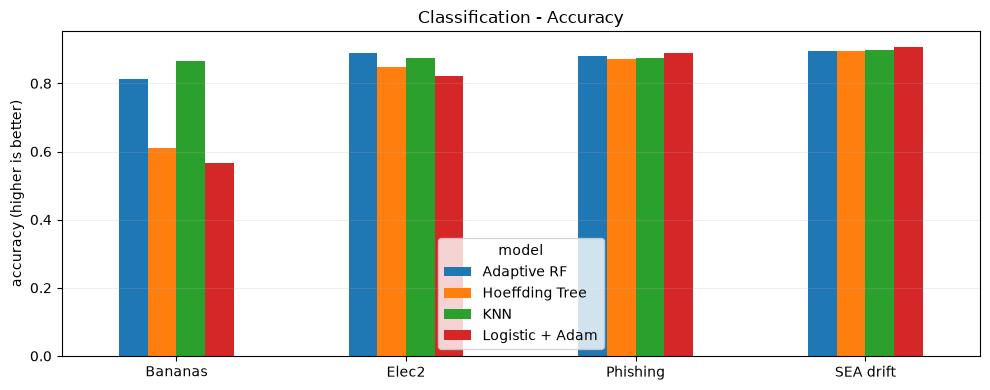

Bananas: KNN (accuracy = 0.866)
Elec2: Adaptive RF (accuracy = 0.890)
Phishing: Logistic + Adam (accuracy = 0.888)
SEA drift: Logistic + Adam (accuracy = 0.907)


In [142]:
bars(cls_results,'accuracy','Classification - Accuracy',higher=True);best_by_dataset(cls_results,'accuracy',True)

### 3.2.2 Macro F1

Macro F1 is the average F1-score across classes, giving each class the same importance. Unlike accuracy, it considers both precision and recall for each class.

The results follow a similar pattern to accuracy:

- Adaptive Random Forest achieves the highest Macro F1 on **Elec2 (0.890)**.
- Logistic Regression + Adam performs best on **Phishing (0.886)** and **SEA drift (0.898)**.
- KNN achieves the best score on **Bananas (0.862)**.

The similarity between the accuracy and Macro F1 rankings suggests that the models performing well overall also tend to provide a reasonable balance between precision and recall across classes.

The difference is particularly noticeable on Bananas: Logistic Regression + Adam obtains a Macro F1 of only **0.501**, compared with **0.862** for KNN. This confirms that the linear classifier struggles on this dataset, while KNN handles its structure much better.

Overall, Macro F1 supports the conclusions obtained from accuracy, while giving a more balanced view of performance across the classes.

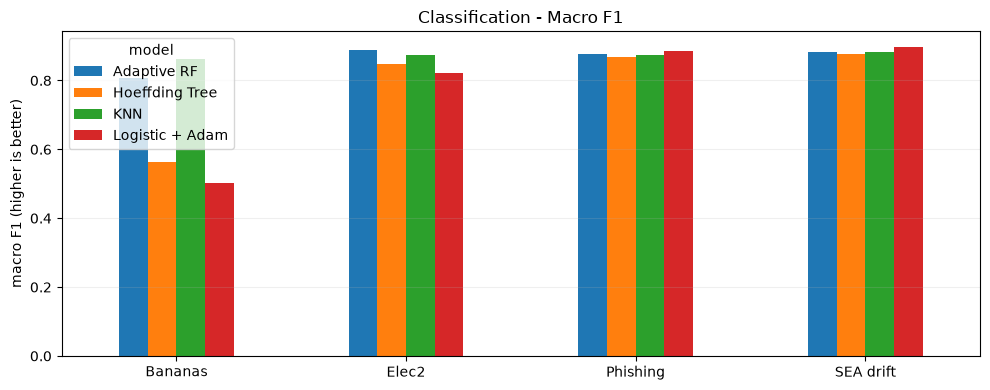

Bananas: KNN (macro F1 = 0.862)
Elec2: Adaptive RF (macro F1 = 0.890)
Phishing: Logistic + Adam (macro F1 = 0.886)
SEA drift: Logistic + Adam (macro F1 = 0.898)


In [143]:
bars(cls_results,'macro F1','Classification - Macro F1',higher=True);best_by_dataset(cls_results,'macro F1',True)

### 3.2.3 Cohen's Kappa

Cohen's Kappa measures agreement between predicted and actual classes while accounting for agreement expected by chance. A value of 1 indicates perfect agreement, while a value around 0 indicates little improvement over chance agreement.

The highest Kappa scores are:

- **Elec2:** Adaptive Random Forest (0.780).
- **Phishing:** Logistic Regression + Adam (0.773).
- **Bananas:** KNN (0.725).
- **SEA drift:** Logistic Regression + Adam (0.796).

These results confirm the rankings observed with accuracy and Macro F1.

The lowest score is obtained by Logistic Regression + Adam on Bananas, with a Kappa of only **0.050**, indicating very limited improvement over chance agreement.

In contrast, the best models achieve Kappa values between 0.725 and 0.796, indicating substantially better agreement.

Since all three classification metrics lead to similar rankings, the main differences between the models appear quite consistent across the evaluation measures.

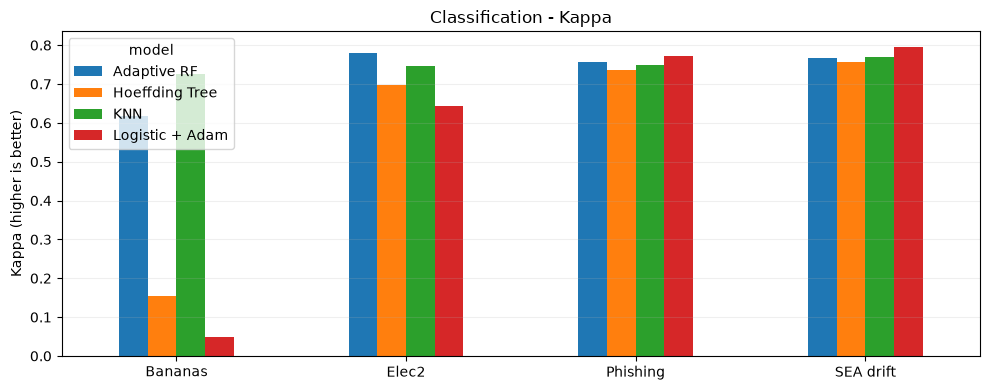

Bananas: KNN (Kappa = 0.725)
Elec2: Adaptive RF (Kappa = 0.780)
Phishing: Logistic + Adam (Kappa = 0.773)
SEA drift: Logistic + Adam (Kappa = 0.796)


In [144]:
bars(cls_results,'Kappa','Classification - Kappa',higher=True);best_by_dataset(cls_results,'Kappa',True)

### 3.2.4 Running time and latency

We also compare the computational cost of the four classifiers. Running time measures the total duration of each experiment, while model latency measures the average time spent on prediction and training for one observation.

**Logistic Regression + Adam is the fastest model on all four datasets.** For example, on SEA drift, it takes only **0.137 seconds**, compared with 2.064 seconds for Adaptive Random Forest and 2.454 seconds for KNN.

The same pattern appears on Elec2, where Logistic Regression takes 0.061 seconds, compared with 0.578 seconds for Adaptive Random Forest and 1.178 seconds for KNN.

KNN is generally the slowest method because it searches for nearest neighbors when making predictions. Adaptive Random Forest also requires more computation because it maintains several trees.

The results highlight an accuracy–cost trade-off. On Elec2, Adaptive Random Forest achieves the highest accuracy, but at a higher computational cost. On Phishing and SEA drift, Logistic Regression + Adam is both the fastest and the most accurate model.

This makes the linear classifier particularly interesting when computational efficiency matters, although its poor performance on Bananas shows that speed alone is not enough to select a model.

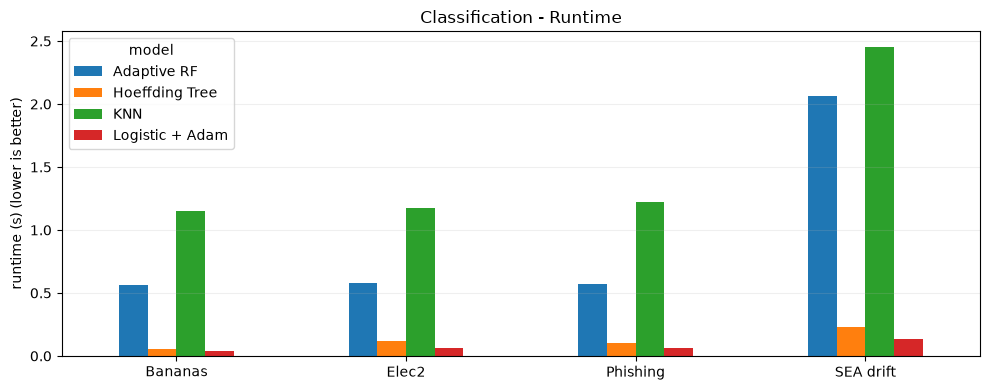

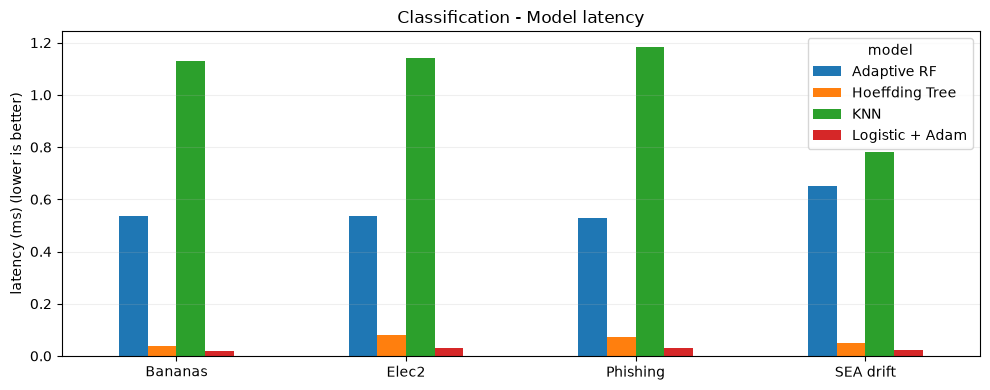

In [145]:
bars(cls_results,'runtime (s)','Classification - Runtime');bars(cls_results,'latency (ms)','Classification - Model latency')

### 3.2.5 Learning curves

The previous metrics summarize performance over the entire stream. To examine how accuracy evolves as new observations arrive, we also plot **rolling accuracy**, calculated over a window of recent predictions.

The curves show that performance is not constant during online learning. Some models improve as they receive more observations, while others show larger fluctuations.

On Bananas, the difference between the models is particularly visible, with KNN achieving better overall performance than the linear classifier.

On SEA drift, the dashed vertical lines mark the changes at observations 1,000 and 2,000. The curves help us examine whether accuracy decreases after these changes and how the models adapt as learning continues.

These plots are useful because cumulative accuracy can hide temporary performance drops. We examine this more closely in the drift-detection section.

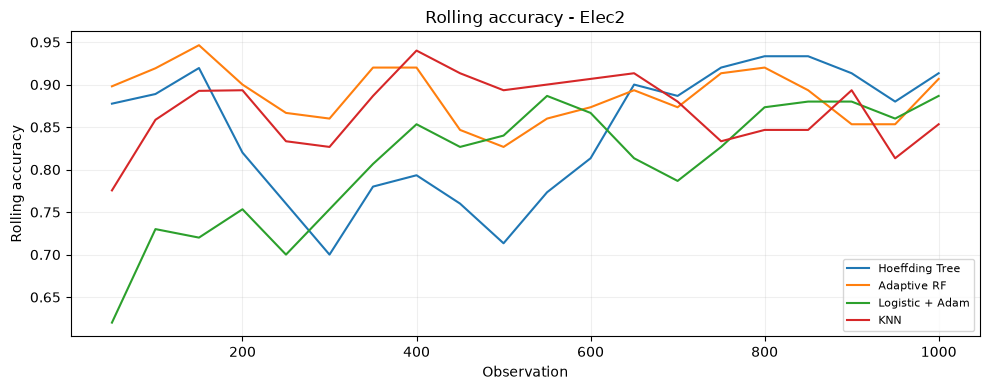

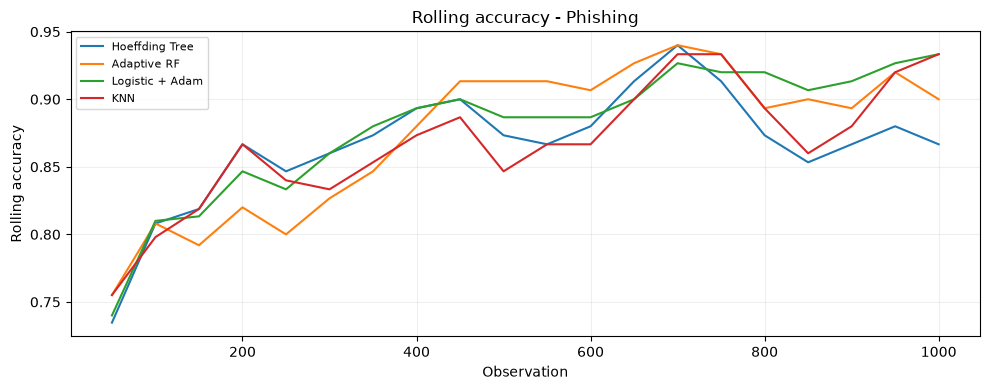

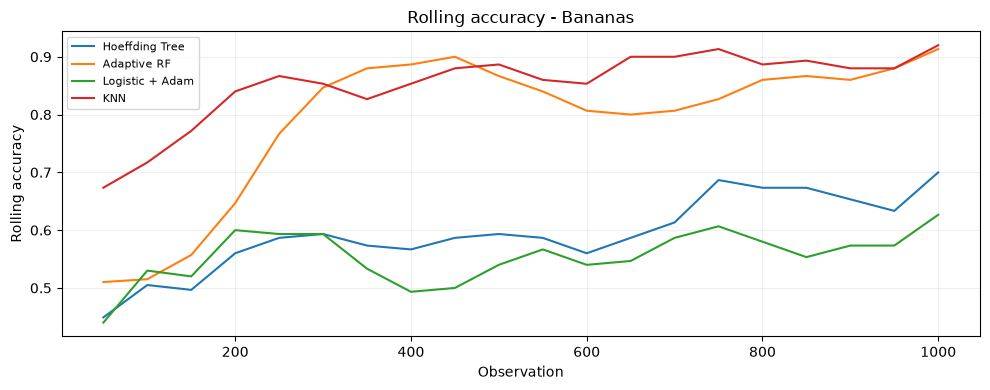

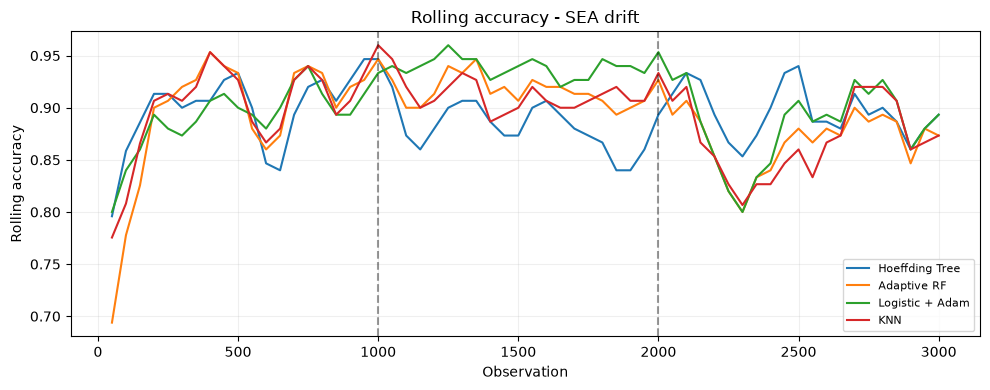

In [146]:
for ds,curves in CLS_CURVES.items():
    plt.figure(figsize=(10,4))
    for name,h in curves.items():plt.plot(h['instance'],h['rolling accuracy'],label=name)
    if ds=='SEA drift':
        for p in DRIFT_POINTS:plt.axvline(p,color='black',ls='--',alpha=.4)
    plt.title('Rolling accuracy - '+ds)
    plt.xlabel('Observation');plt.ylabel('Rolling accuracy')
    plt.legend(fontsize=8);plt.grid(alpha=.2);plt.tight_layout();plt.show()

## 3.3 Drift Detection

We now study concept drift in classification using the synthetic SEA stream, which contains two known changes at observations **1,000 and 2,000**.

We compare three detectors:

- **ADWIN:** detects statistical changes using an adaptive window.
- **DDM:** monitors changes in the classification error rate.
- **EDDM:** monitors the distance between prediction errors to identify changes in performance.

All three detectors receive the same sequence of prediction errors from a Hoeffding Tree, where 0 represents a correct prediction and 1 represents an incorrect one.

We compare the number and positions of detected drifts, as well as the detection delay relative to the known change points.

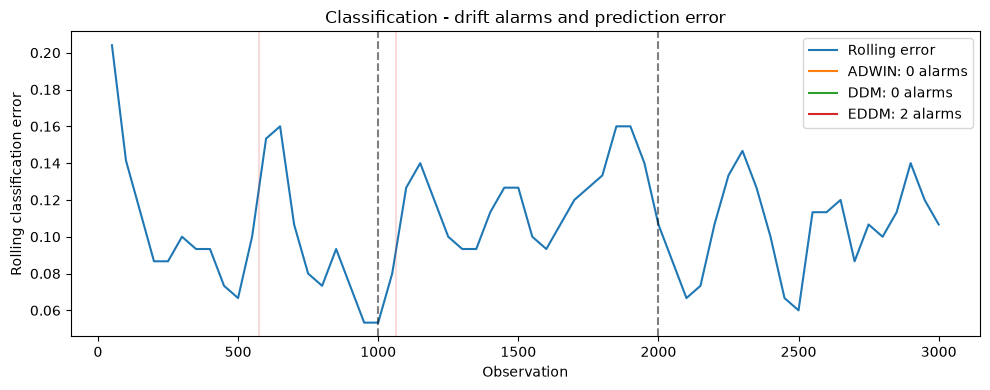

,detector,alarms,positions
0,ADWIN,0,[]
1,DDM,0,[]
2,EDDM,2,"[575, 1064]"


In [147]:
_,sea_curve,sea_errors=run_classification(CLS_MODELS['Hoeffding Tree'],sea_drift,SYNTH_N)
CLS_DETECTORS={'ADWIN':lambda:drift.ADWIN(),
               'DDM':lambda:binary_drift.DDM(),
               'EDDM':lambda:binary_drift.EDDM()}
cls_alarms={name:alarm_positions(sea_errors,factory) for name,factory in CLS_DETECTORS.items()}
plt.figure(figsize=(10,4))
plt.plot(sea_curve['instance'],1-sea_curve['rolling accuracy'],label='Rolling error')
for p in DRIFT_POINTS:plt.axvline(p,color='black',ls='--',alpha=.5)
for j,(name,alarms) in enumerate(cls_alarms.items()):
    for a in alarms:plt.axvline(a,color=['tab:orange','tab:green','tab:red'][j],alpha=.16)
    plt.plot([],[],color=['tab:orange','tab:green','tab:red'][j],label=f'{name}: {len(alarms)} alarms')
plt.title('Classification - drift alarms and prediction error')
plt.xlabel('Observation');plt.ylabel('Rolling classification error')
plt.legend();plt.tight_layout();plt.show()
display(pd.DataFrame([{'detector':k,'alarms':len(v),'positions':str(v[:20])} for k,v in cls_alarms.items()]))

In [148]:
# Classification drift detection delays

cls_delay_results = drift_delay_table(
    cls_alarms,
    DRIFT_POINTS
)

display(cls_delay_results)

,Detector,True drift,Detected at,Delay
0,ADWIN,1000,NaN,NaN
1,ADWIN,2000,NaN,NaN
2,ADWIN,Unmatched alarms,0.0,NaN
3,DDM,1000,NaN,NaN
4,DDM,2000,NaN,NaN
5,DDM,Unmatched alarms,0.0,NaN
6,EDDM,1000,1064.0,64.0
7,EDDM,2000,NaN,NaN
8,EDDM,Unmatched alarms,1.0,NaN


### Drift detection results

The detectors behave quite differently on SEA drift.

**ADWIN and DDM do not raise any alarms** during the experiment. This means that neither detector identifies the two known changes with the current configurations.

**EDDM raises two alarms**, at observations 575 and 1,064. The first alarm occurs before the known drift at observation 1,000, so it is not matched to either known change. The second alarm detects the first drift with a delay of **64 observations**.

However, EDDM does not detect the second drift at observation 2,000 within the 300-observation matching window.

Compared with the regression experiment, detecting drift appears more difficult here. The prediction errors may not change enough for every detector to raise an alarm, especially if the classifier continues adapting to the new concept.

EDDM is the only detector that identifies one of the known drift points in this experiment, but its early unmatched alarm also shows that greater sensitivity does not necessarily mean more reliable detection.

### Effect of resetting the classifier

To investigate whether drift detection can improve classification performance, we compare two Hoeffding Tree strategies:

- **No reset:** the model continues learning throughout the stream.
- **Reset after EDDM:** the model is reinitialized whenever EDDM detects a change.

We use EDDM because it is the only detector that raised alarms near a known drift in the previous experiment.

The experiment compares rolling accuracy to see whether resetting helps the model adapt more quickly or causes it to lose useful information from earlier observations.

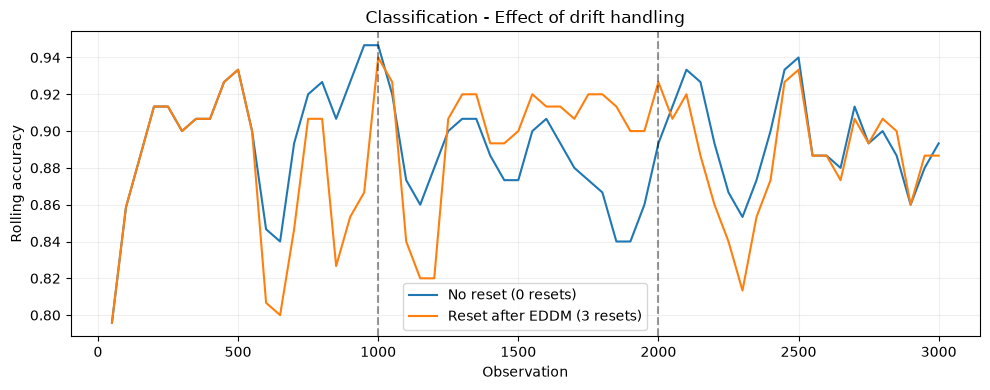

In [149]:
# Compare classification with and without EDDM resets

def classification_reset(reset):
    model = CLS_MODELS['Hoeffding Tree']()
    detector = binary_drift.EDDM()

    recent = deque(maxlen=WINDOW)
    xs, ys, alarms = [], [], []

    for i, (x, y) in enumerate(sea_drift(), 1):

        # Predict before training
        pred = model.predict_one(x)

        if pred is not None:
            error = int(y != pred)
            recent.append(1 - error)

            if reset:
                detector.update(error)

                if detector.drift_detected:
                    alarms.append(i)
                    model = CLS_MODELS['Hoeffding Tree']()
                    detector = binary_drift.EDDM()

        model.learn_one(x, y)

        if i % 50 == 0 and recent:
            xs.append(i)
            ys.append(np.mean(recent))

    return xs, ys, alarms


plt.figure(figsize=(10, 4))

for title, reset in [
    ('No reset', False),
    ('Reset after EDDM', True)
]:
    xs, ys, alarms = classification_reset(reset)

    plt.plot(
        xs, ys,
        label=f'{title} ({len(alarms)} resets)'
    )

for p in DRIFT_POINTS:
    plt.axvline(
        p, color='black',
        linestyle='--', alpha=0.4
    )

plt.title('Classification - Effect of drift handling')
plt.xlabel('Observation')
plt.ylabel('Rolling accuracy')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**Conclusion - Classification drift detection**

The results show that detecting concept drift in classification is not always straightforward. ADWIN and DDM do not detect either known change, while EDDM identifies the first drift with a delay of 64 observations but misses the second one.

In the drift-handling experiment, **EDDM triggers three model resets**. Looking at the rolling-accuracy curves, resetting sometimes improves performance, but it also causes temporary drops, particularly after the first drift.

The two strategies remain relatively close over several parts of the stream, and neither consistently outperforms the other.

This suggests that resetting the classifier is not automatically beneficial. Although a detector may identify changes in the prediction errors, resetting also removes previously learned information.

Overall, the experiment shows that effective drift handling depends not only on detecting changes, but also on deciding when adapting or resetting the model is actually useful.

# 4. Part 3: CapyMOA

## 4.1 Classification comparison

In this section, we compare River and CapyMOA on the same four classification datasets: Elec2, Phishing, Bananas and SEA drift.

We use four model families in both libraries: Hoeffding Tree, Adaptive Random Forest, an online linear classifier and KNN. The objective is to compare not only predictive performance but also processing time and latency.

To keep the comparison consistent, we use the same observations in the same order: 1,000 for each real dataset and 3,000 for SEA drift. Features are converted into numerical arrays, and class labels are encoded as integers for CapyMOA.

However, the implementations are not exactly identical. For example, River uses Logistic Regression with Adam, while CapyMOA uses SGD with logistic loss. The models also differ in some default parameters, and CapyMOA's KNN uses a window of 500 observations.

Therefore, this experiment compares the practical performance of similar algorithm families in the two libraries, rather than perfectly identical implementations.

One preprocessing limitation is that the numerical feature vocabulary is constructed using the complete stream before CapyMOA evaluation. This does not use future target labels for model training, but it is not strictly online feature preprocessing.

In [150]:
# Prepare the same examples for both libraries, without changing their order.
SHARED={}
for ds,make_data in CLS_DATA.items():
    limit=SYNTH_N if ds=='SEA drift' else REAL_N
    pairs=[]
    for i,(raw_x,y) in enumerate(make_data()):
        if i>=limit:break
        pairs.append((features(raw_x),y))
    vectorizer=DictVectorizer(sparse=False)
    X=vectorizer.fit_transform([x for x,y in pairs]).astype(np.float64)
    # CapyMOA NumpyStream requires integer-coded categorical labels.
    labels,encoded=np.unique(np.array([y for x,y in pairs]),return_inverse=True)
    SHARED[ds]=(X,encoded.astype(np.int64),list(vectorizer.get_feature_names_out()))
    print(f'{ds}: {X.shape[0]} observations, {X.shape[1]} numeric features, {len(labels)} classes')

CAPY_MODELS={
    'Hoeffding Tree':lambda schema:CapyHT(schema=schema),
    'Adaptive RF':lambda schema:CapyARF(schema=schema,ensemble_size=5),
    'SGD (logistic loss)':lambda schema:CapySGD(schema=schema,loss='log_loss',random_seed=SEED),
    'KNN':lambda schema:CapyKNN(schema=schema,k=5,window_size=500),
}

Elec2: 1000 observations, 8 numeric features, 2 classes
Phishing: 1000 observations, 9 numeric features, 2 classes
Bananas: 1000 observations, 2 numeric features, 2 classes
SEA drift: 3000 observations, 3 numeric features, 2 classes


We evaluate the four CapyMOA classifiers using prequential evaluation, where each observation is predicted before being used for training.

For each model and dataset, we record accuracy, total processing time and average latency per observation. These results are then combined with the River results from Part 2 to compare the two libraries.

In [151]:
CAPY_ROWS=[]
for ds,(X,y,feature_names) in SHARED.items():
    for name,make_model in CAPY_MODELS.items():
        print(f'Running CapyMOA: {ds} - {name}',flush=True)
        stream=NumpyStream(X,y,feature_names=feature_names,dataset_name=ds,target_type='categorical')
        learner=make_model(stream.get_schema())
        start=time.perf_counter()
        evaluation=prequential_evaluation(stream=stream,learner=learner,
                                          window_size=WINDOW,max_instances=len(y))
        elapsed=time.perf_counter()-start
        CAPY_ROWS.append({'dataset':ds,'model':name,'library':'CapyMOA',
                          'accuracy':evaluation.cumulative.accuracy()/100,
                          'runtime (s)':elapsed,
                          'latency (ms)':1000*elapsed/len(y),
                          'observations':len(y)})
        pd.DataFrame(CAPY_ROWS).to_csv('results/capymoa_classification.csv',index=False)
        print(f'Finished in {elapsed:.2f}s',flush=True)
capy_results=pd.DataFrame(CAPY_ROWS)
river_results=cls_results.copy()
river_results['library']='River'
# End-to-end latency = total evaluation time divided by observation count.
river_results['latency (ms)']=1000*river_results['runtime (s)']/river_results['observations']
cross_results=pd.concat([river_results,capy_results],ignore_index=True)
display(cross_results[['dataset','model','library','accuracy','runtime (s)','latency (ms)']].round(3))

Running CapyMOA: Elec2 - Hoeffding Tree
Finished in 0.10s
Running CapyMOA: Elec2 - Adaptive RF
Finished in 0.32s
Running CapyMOA: Elec2 - SGD (logistic loss)
Finished in 1.36s
Running CapyMOA: Elec2 - KNN
Finished in 0.16s
Running CapyMOA: Phishing - Hoeffding Tree
Finished in 0.19s
Running CapyMOA: Phishing - Adaptive RF
Finished in 0.26s
Running CapyMOA: Phishing - SGD (logistic loss)
Finished in 1.25s
Running CapyMOA: Phishing - KNN
Finished in 0.14s
Running CapyMOA: Bananas - Hoeffding Tree
Finished in 0.09s
Running CapyMOA: Bananas - Adaptive RF
Finished in 0.25s
Running CapyMOA: Bananas - SGD (logistic loss)
Finished in 1.33s
Running CapyMOA: Bananas - KNN
Finished in 0.12s
Running CapyMOA: SEA drift - Hoeffding Tree
Finished in 0.28s
Running CapyMOA: SEA drift - Adaptive RF
Finished in 0.59s
Running CapyMOA: SEA drift - SGD (logistic loss)
Finished in 3.84s
Running CapyMOA: SEA drift - KNN
Finished in 0.38s


,dataset,model,library,accuracy,runtime (s),latency (ms)
0,Elec2,Hoeffding Tree,River,0.848,0.118,0.118
1,Elec2,Adaptive RF,River,0.890,0.578,0.578
2,Elec2,Logistic + Adam,River,0.822,0.061,0.061
3,Elec2,KNN,River,0.874,1.178,1.178
4,Phishing,Hoeffding Tree,River,0.871,0.106,0.106
5,Phishing,Adaptive RF,River,0.881,0.570,0.570
6,Phishing,Logistic + Adam,River,0.888,0.064,0.064
7,Phishing,KNN,River,0.876,1.223,1.223
8,Bananas,Hoeffding Tree,River,0.610,0.055,0.055
9,Bananas,Adaptive RF,River,0.814,0.563,0.563


### 4.1.1 Accuracy

We first compare the classification accuracy obtained by both libraries.

The results show that neither library consistently outperforms the other.

On **Elec2**, River's Adaptive Random Forest achieves 89.0% accuracy, compared with 86.1% for CapyMOA. However, CapyMOA's Hoeffding Tree performs better than River's, reaching 87.6% compared with 84.8%.

On **Phishing**, the highest accuracy is obtained by CapyMOA's Adaptive Random Forest (89.1%), slightly above River's Logistic Regression + Adam (88.8%). The largest difference appears between the linear classifiers: River achieves 88.8%, while CapyMOA's SGD reaches 82.5%.

On **Bananas**, KNN performs best in both libraries, reaching 86.6% with River and 88.0% with CapyMOA. This is consistent with the results from Part 2, where KNN was particularly effective on this nonlinear dataset.

Finally, on **SEA drift**, CapyMOA's KNN reaches 90.8%, while River's Logistic Regression + Adam achieves 90.7%. CapyMOA's SGD performs noticeably worse, with 79.0% accuracy.

Across all 16 model-dataset combinations, the mean accuracy is **83.7% for River and 82.8% for CapyMOA**.

The difference is small, and the results suggest that performance depends more on the model and dataset combination than on the library alone. These averages are descriptive and should not be interpreted as proof that one library is generally more accurate.

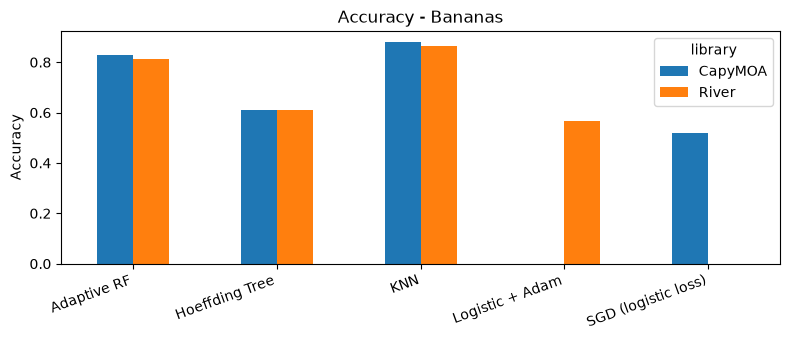

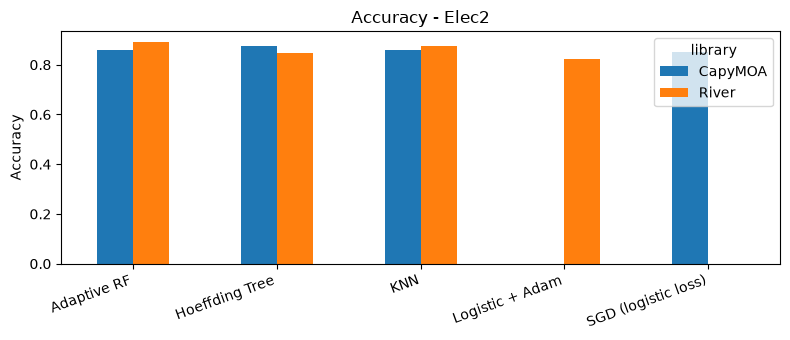

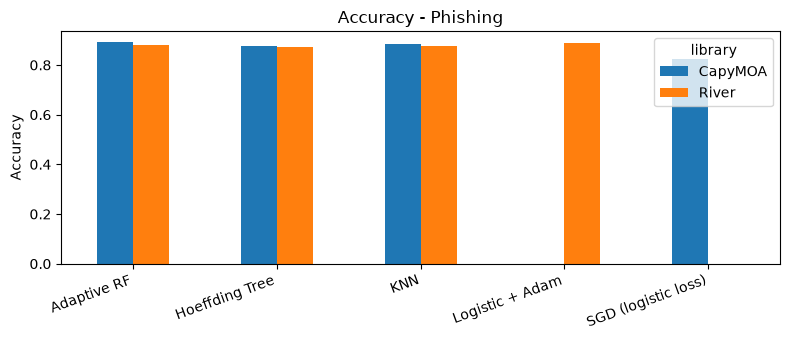

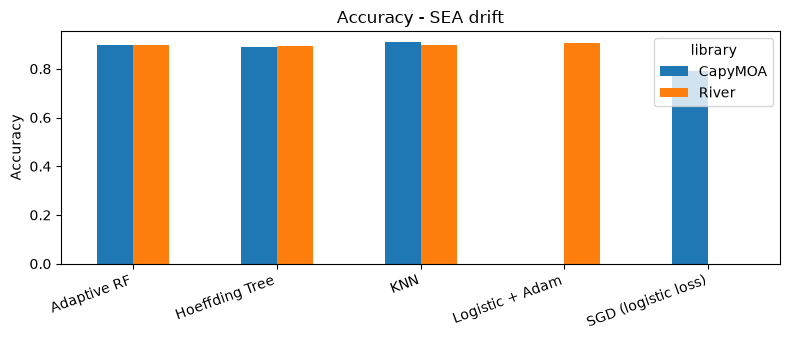

In [152]:
for ds,g in cross_results.groupby('dataset'):
    g.pivot(index='model',columns='library',values='accuracy').plot(kind='bar',figsize=(8,3.5))
    plt.title('Accuracy - '+ds);plt.ylabel('Accuracy')
    plt.xlabel('');plt.xticks(rotation=20,ha='right');plt.tight_layout();plt.show()

### 4.1.2 Processing time

We now compare the total time required to process each dataset. This includes the evaluation loop and stream handling, not just the model's internal computations.

The results show some clear differences between River and CapyMOA.

CapyMOA is substantially faster for **KNN**. On Elec2, KNN takes **0.160 seconds** with CapyMOA, compared with **1.178 seconds** with River. On SEA drift, the difference is even larger: 0.376 seconds compared with 2.454 seconds.

CapyMOA's Adaptive Random Forest is also generally faster. On SEA drift, it takes 0.588 seconds, while River requires 2.064 seconds.

However, the opposite happens with the linear classifiers. On SEA drift, River's Logistic Regression + Adam takes only 0.137 seconds, compared with 3.844 seconds for CapyMOA's SGD with logistic loss. We observe the same pattern on the other datasets.

The Hoeffding Tree implementations have more similar running times, although the differences vary depending on the dataset.

Overall, CapyMOA performs particularly well for KNN and Adaptive Random Forest, while River is considerably faster for the tested linear classifier.

These differences may come from the implementations, model configurations and preprocessing, so they should not be interpreted as a general speed ranking of the two libraries.

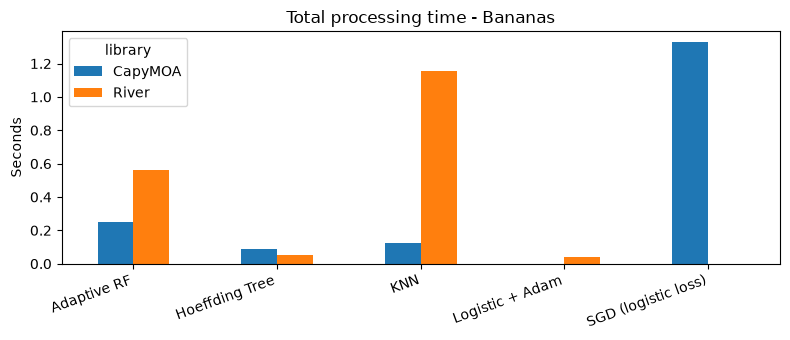

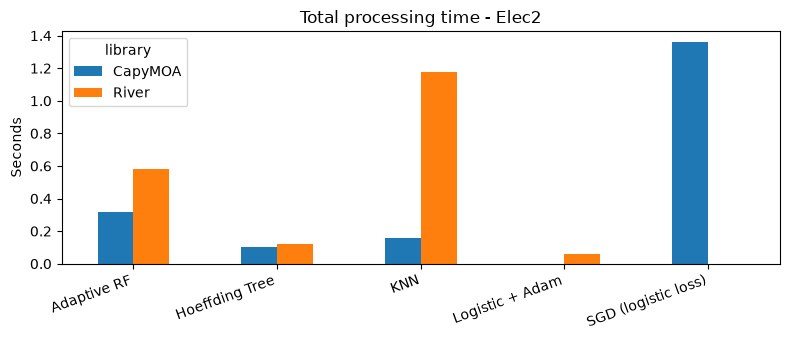

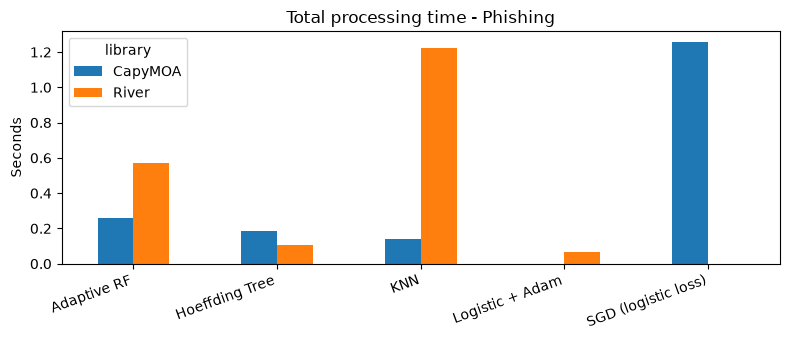

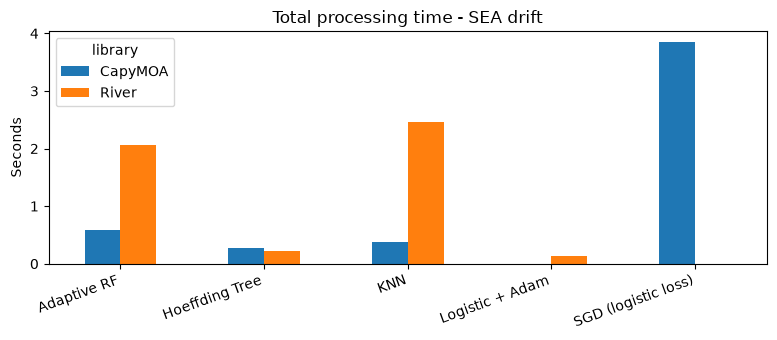

In [153]:
for ds,g in cross_results.groupby('dataset'):
    g.pivot(index='model',columns='library',values='runtime (s)').plot(kind='bar',figsize=(8,3.5))
    plt.title('Total processing time - '+ds);plt.ylabel('Seconds')
    plt.xlabel('');plt.xticks(rotation=20,ha='right');plt.tight_layout();plt.show()

### 4.1.3 Latency

Latency measures the average time required to process one observation. In this comparison, we calculate it by dividing total evaluation time by the number of observations, expressed in milliseconds.

The results follow the same pattern as processing time.

On **SEA drift**, CapyMOA's KNN has a latency of **0.125 ms per observation**, compared with **0.818 ms** for River. CapyMOA's Adaptive Random Forest also processes observations faster, with 0.196 ms compared with 0.688 ms for River.

In contrast, River's Logistic Regression + Adam is considerably faster than CapyMOA's SGD, with latencies of 0.046 ms and 1.281 ms respectively.

These differences matter in streaming applications, where observations may arrive continuously and models need to update quickly.

However, the reported values represent average end-to-end processing time, not individual prediction latency. They also depend on the model implementation, hardware and execution conditions.

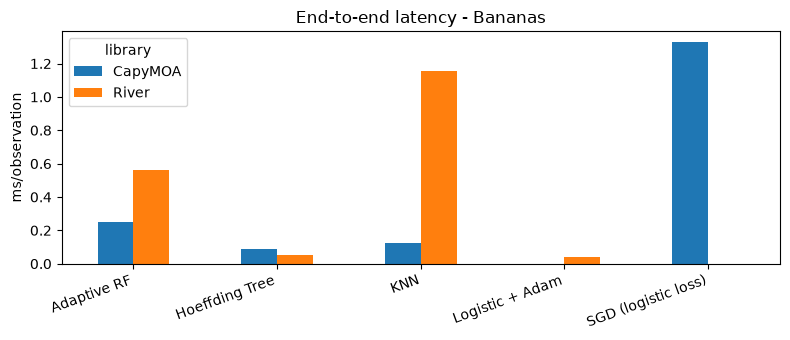

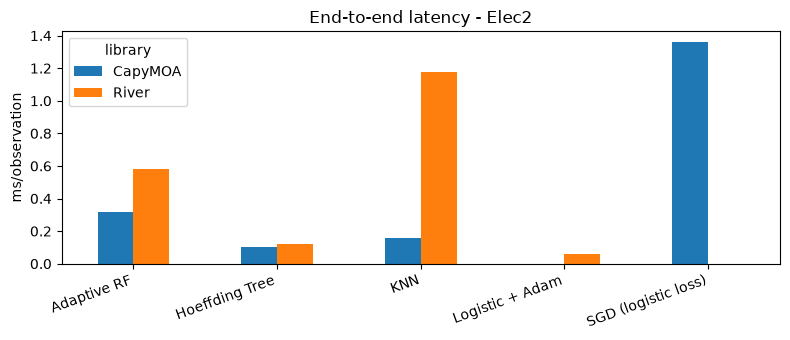

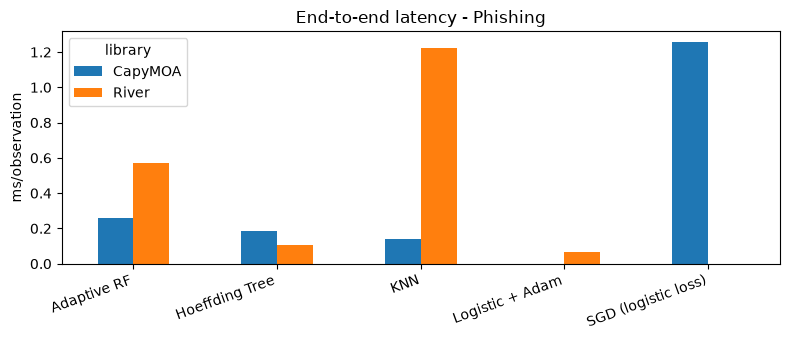

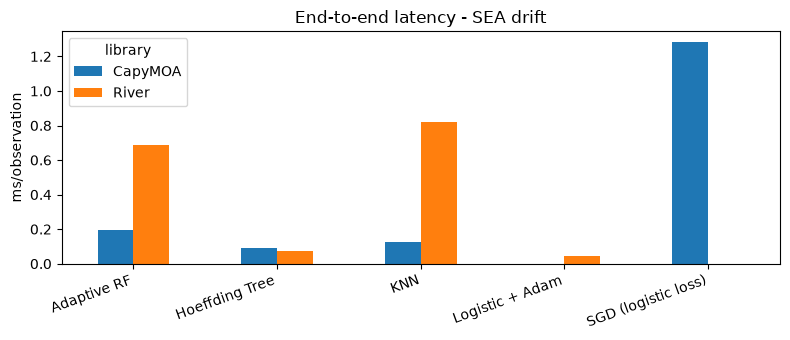

Mean accuracy by library:


library
CapyMOA    0.828
River      0.837
Name: accuracy, dtype: float64

In [154]:
for ds,g in cross_results.groupby('dataset'):
    g.pivot(index='model',columns='library',values='latency (ms)').plot(kind='bar',figsize=(8,3.5))
    plt.title('End-to-end latency - '+ds);plt.ylabel('ms/observation')
    plt.xlabel('');plt.xticks(rotation=20,ha='right');plt.tight_layout();plt.show()

print('Mean accuracy by library:')
display(cross_results.groupby('library')['accuracy'].mean().round(3))

**Conclusion - River vs CapyMOA**

The comparison shows that both libraries achieve similar overall classification accuracy, although individual algorithms can behave quite differently.

CapyMOA is particularly efficient for KNN and Adaptive Random Forest in our experiments, while River performs much faster with its Adam-based linear classifier. For accuracy, neither library consistently dominates across all datasets.

The main takeaway is that the choice of algorithm has a major impact on both accuracy and computational cost. The library also matters, but differences in implementation and hyperparameters must be considered before drawing general conclusions.

For a real-time application, I would therefore select the model and library together, based on the dataset characteristics and the required processing speed.

## 4.2 Clustering

We now explore unsupervised learning on data streams using two clustering methods from CapyMOA:

- **CluStream + KMeans:** maintains compact summaries of the incoming data and uses KMeans to form clusters.
- **DenStream + DBSCAN:** uses a density-based approach to identify clusters and handle noisy observations.

We use synthetic data generated with RandomRBFGeneratorDrift, with five and eight cluster centers. In both cases, two centers gradually move as new observations arrive, allowing us to study how the clustering methods respond to evolving data.

Each model processes 300 observations, and we visualize its state after 150 and 300 observations.

The objective is to examine how the cluster structures evolve and compare the computational cost of the two approaches.

5 centers | CluStream + KMeans | after 150 instances


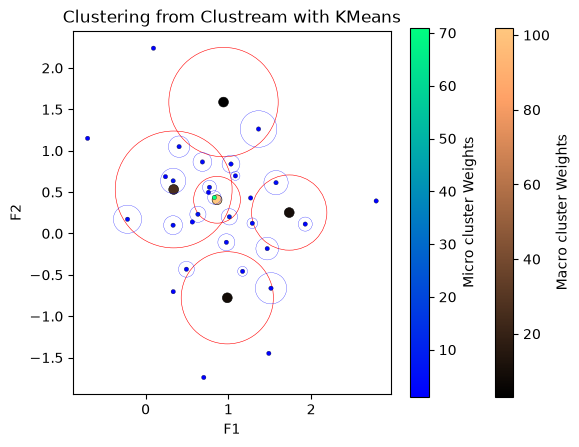

5 centers | CluStream + KMeans | after 300 instances


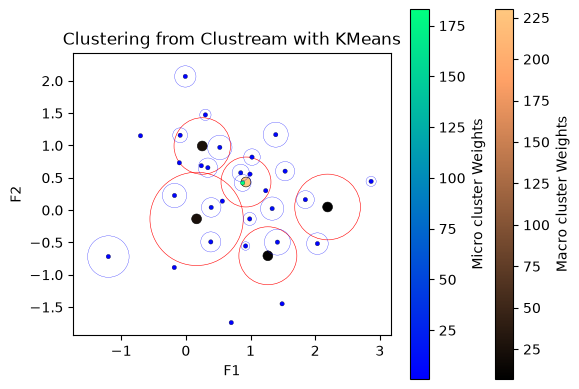

5 centers | DenStream + DBSCAN | after 150 instances


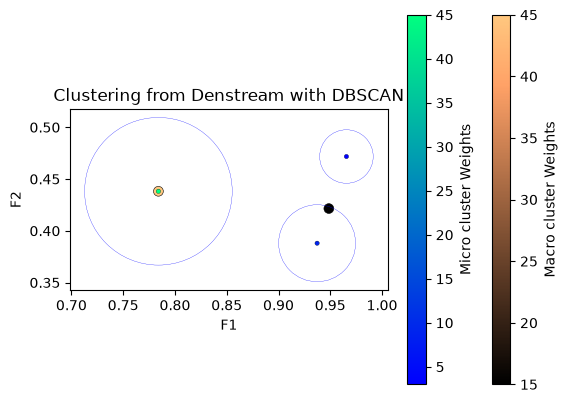

5 centers | DenStream + DBSCAN | after 300 instances


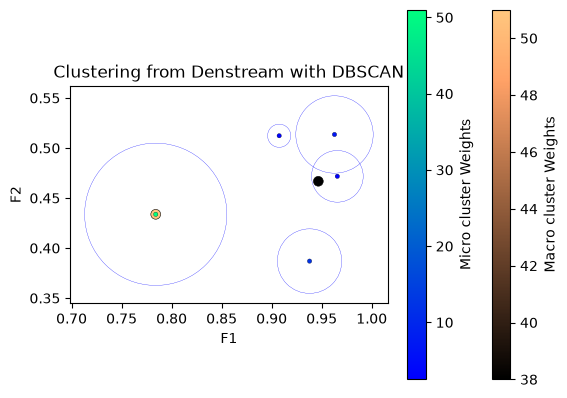

8 centers | CluStream + KMeans | after 150 instances


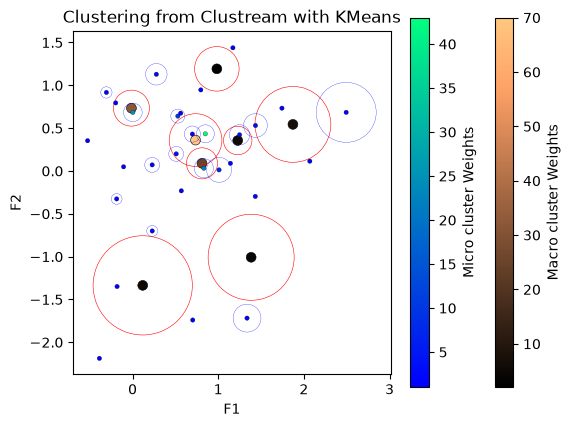

8 centers | CluStream + KMeans | after 300 instances


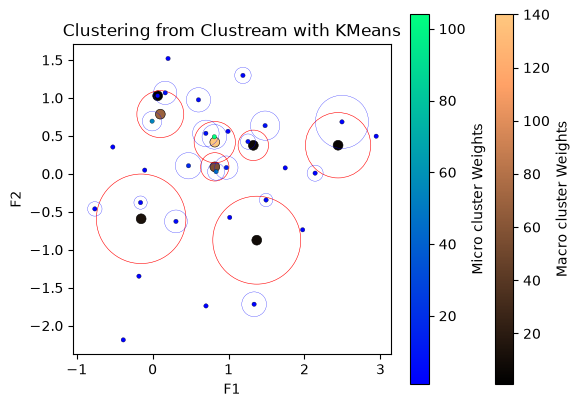

8 centers | DenStream + DBSCAN | after 150 instances


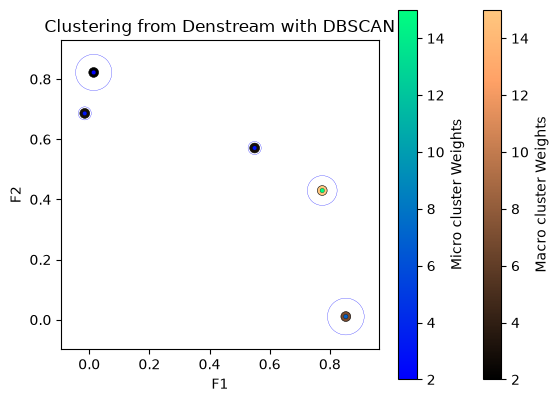

8 centers | DenStream + DBSCAN | after 300 instances


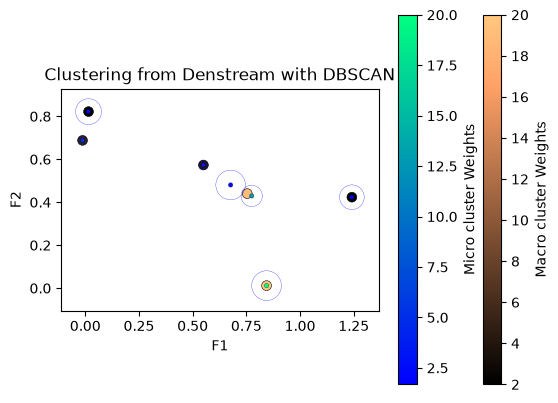

,dataset,model,runtime (s),latency (ms)
0,RBF 5 centers,CluStream + KMeans,0.586,1.953
1,RBF 5 centers,DenStream + DBSCAN,0.440,1.467
2,RBF 8 centers,CluStream + KMeans,0.643,2.142
3,RBF 8 centers,DenStream + DBSCAN,0.555,1.851


In [155]:
from capymoa.stream.generator import RandomRBFGeneratorDrift
from capymoa.cluster import Clustream_with_kmeans, Denstream_with_dbscan
from capymoa.evaluation.visualization import plot_clustering_state

CLUSTER_ROWS=[]
for centers in [5,8]:
    for name in ['CluStream + KMeans','DenStream + DBSCAN']:
        stream=RandomRBFGeneratorDrift(number_of_attributes=2,
            number_of_centroids=centers,number_of_drifting_centroids=2,
            magnitude_of_change=.001)
        schema=stream.get_schema()
        if name=='CluStream + KMeans':
            model=Clustream_with_kmeans(schema=schema,time_window=1000,
                max_num_kernels=30,kernel_radi_factor=2,k_option=centers)
        else:
            model=Denstream_with_dbscan(schema=schema,horizon=1000,
                epsilon=.04,beta=.2,mu=1.2,init_points=100,
                offline_option=3,lambda_option=.25,speed=200)
        start=time.perf_counter()
        for i in range(1,301):
            model.train(stream.next_instance())
            if i in (150,300):
                print(f'{centers} centers | {name} | after {i} instances')
                plot_clustering_state(model)
        elapsed=time.perf_counter()-start
        CLUSTER_ROWS.append({'dataset':f'RBF {centers} centers','model':name,
                             'runtime (s)':elapsed,'latency (ms)':1000*elapsed/300})
cluster_results=pd.DataFrame(CLUSTER_ROWS)
cluster_results.to_csv('results/capymoa_clustering.csv',index=False)
display(cluster_results.round(3))

### 4.2.1 Cluster quality and evolution

To examine how the clustering methods behave over time, we visualize their cluster states after 150 and 300 observations.

CluStream + KMeans and DenStream + DBSCAN use different approaches. CluStream summarizes incoming observations into microclusters before forming larger groups, while DenStream relies on local density to identify clusters.

The synthetic streams contain either five or eight underlying centers, making it possible to examine how the clustering methods represent data with different levels of complexity.

The visualizations allow us to compare the grouping of observations at the two checkpoints and inspect how the cluster representations change as more data arrives. However, the movement of the underlying centers is gradual, and the experiment covers only 300 observations, so the observed differences should not be interpreted as a complete assessment of long-term drift adaptation.

In this experiment, cluster quality is evaluated qualitatively through the visualizations rather than using a numerical score such as silhouette or adjusted Rand index. We therefore cannot establish a definitive accuracy ranking between the two clustering methods.

The results mainly illustrate two different strategies for maintaining clusters in a changing data stream.

Since the two methods use separately generated streams without an explicitly fixed generator seed, the visual comparison is exploratory rather than a strictly controlled evaluation on identical observations.

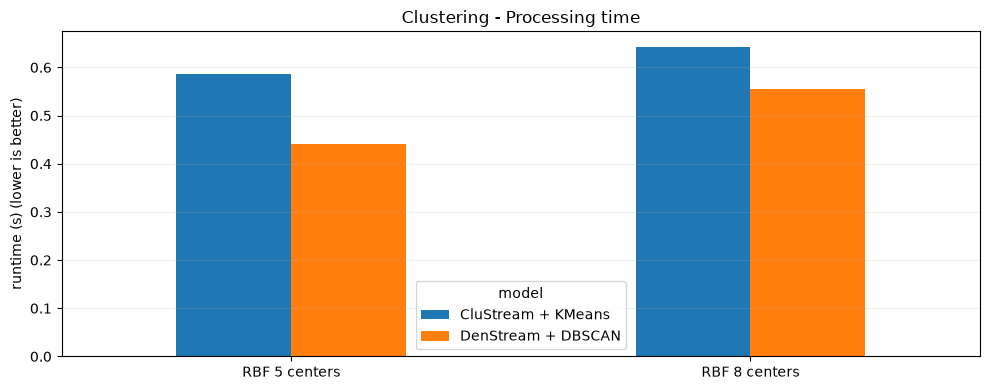

In [156]:
bars(cluster_results,'runtime (s)','Clustering - Processing time')

### 4.2.2 Processing time

We also compare the time required to run the clustering experiments on 300 observations.

With **five centers**, CluStream + KMeans takes **0.586 seconds**, compared with **0.440 seconds** for DenStream + DBSCAN.

With **eight centers**, CluStream takes **0.643 seconds**, while DenStream requires **0.555 seconds**.

DenStream has the lowest recorded running time in both experiments. Increasing the number of centers from five to eight also increases the measured time for both methods.

However, the timing includes the generation of intermediate clustering visualizations at observations 150 and 300. It therefore represents the total experiment duration rather than the clustering algorithm's processing time alone.

**Conclusion - Clustering**

The experiments illustrate how two different clustering approaches represent evolving data streams. DenStream has a lower total runtime in our tests, while the visualizations provide a qualitative view of how the cluster structures evolve.

A more complete comparison would require identical input streams, isolated algorithm timings, longer experiments and quantitative clustering-quality metrics.

## 4.3 AutoML

Finally, we explore online AutoML using CapyMOA.

Unlike the previous experiments, where we selected a fixed algorithm in advance, AutoML aims to select or allocate resources between learning algorithms while the stream is being processed.

We compare three approaches:

- **Fixed Hoeffding Tree:** a baseline that uses the same classifier throughout the stream.
- **BanditClassifier:** an online selection approach that uses a bandit strategy to manage candidate classifiers.
- **SuccessiveHalvingClassifier:** an approach that progressively allocates resources to promising candidates.

For the two AutoML methods, we use Hoeffding Tree and Naive Bayes as candidate classifiers.

All methods are evaluated on the same 3,000 observations from SEA drift, using accuracy, total running time and latency.

The objective is to see whether online model selection improves prediction accuracy enough to justify its additional computational cost.

In [157]:
from capymoa.automl import BanditClassifier, SuccessiveHalvingClassifier
from capymoa.classifier import NaiveBayes as CapyNB

X,y,feature_names=SHARED['SEA drift']
CANDIDATES=[CapyHT,CapyNB]
AUTO_ROWS=[]
for name in ['Fixed Hoeffding Tree','Bandit','Successive Halving']:
    stream=NumpyStream(X,y,feature_names=feature_names,
                       dataset_name='SEA AutoML',target_type='categorical')
    schema=stream.get_schema()
    if name=='Fixed Hoeffding Tree':
        learner=CapyHT(schema=schema)
    elif name=='Bandit':
        learner=BanditClassifier(schema=schema,base_classifiers=CANDIDATES,random_seed=SEED)
    else:
        learner=SuccessiveHalvingClassifier(schema=schema,base_classifiers=CANDIDATES,
                                            random_seed=SEED,max_instances=len(y))
    start=time.perf_counter()
    evaluation=prequential_evaluation(stream=stream,learner=learner,
                                      window_size=WINDOW,max_instances=len(y))
    elapsed=time.perf_counter()-start
    AUTO_ROWS.append({'method':name,'accuracy':evaluation.cumulative.accuracy()/100,
                      'runtime (s)':elapsed,'latency (ms)':1000*elapsed/len(y)})
    pd.DataFrame(AUTO_ROWS).to_csv('results/capymoa_automl.csv',index=False)
    print('Finished:',name)
auto_results=pd.DataFrame(AUTO_ROWS)
display(auto_results.round(3))

Finished: Fixed Hoeffding Tree
Finished: Bandit
Finished: Successive Halving


,method,accuracy,runtime (s),latency (ms)
0,Fixed Hoeffding Tree,0.889,0.288,0.096
1,Bandit,0.898,17.880,5.960
2,Successive Halving,0.894,26.050,8.683


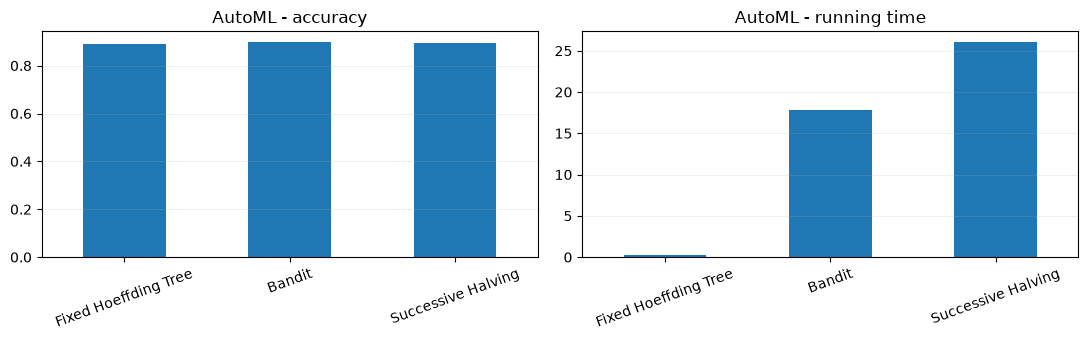

In [158]:
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
auto_results.plot.bar(x='method',y='accuracy',ax=axes[0],legend=False,title='AutoML - accuracy')
auto_results.plot.bar(x='method',y='runtime (s)',ax=axes[1],legend=False,title='AutoML - running time')
for ax in axes:
    ax.set_xlabel('');ax.tick_params(axis='x',labelrotation=20);ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.show()

### AutoML results

The AutoML methods achieve slightly higher accuracy than the fixed Hoeffding Tree:

- **Fixed Hoeffding Tree:** 88.9% accuracy.
- **Bandit:** 89.8% accuracy.
- **Successive Halving:** 89.4% accuracy.

Bandit obtains the best accuracy, improving the baseline by **0.9 percentage points**, while Successive Halving improves it by 0.5 percentage points.

However, these improvements come at a considerable computational cost.

The fixed Hoeffding Tree takes only **0.288 seconds**, compared with **17.880 seconds for Bandit** and **26.050 seconds for Successive Halving**.

Both AutoML approaches therefore require substantially more processing time for a relatively small accuracy improvement. Bandit performs better than Successive Halving in this experiment, achieving higher accuracy with lower runtime.

**Conclusion - AutoML**

The results show that online model selection can improve predictive performance, but the improvement is not necessarily large enough to compensate for its computational cost.

In our experiment, the fixed Hoeffding Tree remains an attractive choice because it achieves competitive accuracy with much lower latency.

AutoML may be more useful when the best algorithm is not known in advance or when changes in the stream make adaptive model selection valuable. However, this experiment suggests that its additional computational cost should be justified by a meaningful performance gain.

## Final conclusion

In this lab, we compared several online learning algorithms using River and CapyMOA, considering both predictive performance and computational cost.

The regression and classification experiments showed that no single model performs best on every dataset. More complex models, such as Adaptive Random Forest, can achieve strong results, but simpler approaches are sometimes equally competitive and much faster.

The drift-detection experiments also showed that identifying changes is not always straightforward. Some detectors react quickly but generate additional alarms, while resetting a model does not necessarily improve its performance.

The River-CapyMOA comparison highlighted differences in execution time between implementations, particularly for KNN, Adaptive Random Forest and linear classifiers. The clustering experiments illustrated how stream clustering methods represent evolving data, while AutoML showed that small accuracy improvements can require substantially more computation.

Overall, the experiments suggest that selecting an online learning method requires considering the data characteristics, possible concept drift and available computational resources together.